<div style="background:linear-gradient(135deg,#1E88C8 0%,#6EC6F0 100%);color:#ffffff;padding:34px 40px;border-radius:14px;font-family:Georgia,'Times New Roman',serif;">
  <table style="width:100%;border:none;background:transparent;"><tr style="background:transparent;">
    <td style="border:none;background:transparent;text-align:left;vertical-align:middle;">
      <div style="font-size:13px;letter-spacing:3px;text-transform:uppercase;font-family:Arial,sans-serif;">Python pour la data science · 2ᵉ année</div>
    </td>
    <td style="border:none;background:transparent;text-align:right;vertical-align:middle;width:180px;">
      <img src="figures/logo_ensae.png" alt="ENSAE Paris" style="height:62px;background:#ffffff;padding:8px 12px;border-radius:8px;">
    </td>
  </tr></table>
  <h1 style="color:#ffffff;font-size:40px;margin:22px 0 6px 0;border:none;">Isolement des communes françaises</h1>
  <div style="font-size:20px;margin-bottom:18px;">Mesure des distances aux services de base et cartographie</div>
  <div style="border-top:1px solid rgba(255,255,255,0.6);padding-top:14px;font-size:16px;font-style:italic;">
    À quelle distance de chez soi trouve-t-on les services du quotidien, et quelles communes sont les plus éloignées de tout ?
  </div>
</div>

<br>

<div style="border-left:6px solid #1E88C8;background:#EAF6FD;padding:20px 28px;border-radius:0 12px 12px 0;font-family:Arial,sans-serif;color:#12324a;">
  <div style="font-size:13px;letter-spacing:2.5px;text-transform:uppercase;color:#1E88C8;margin-bottom:6px;">Équipe</div>
  <div style="font-size:15px;margin-bottom:14px;">Projet réalisé dans le cadre du cours de Python de 2ᵉ année à l'ENSAE Paris.</div>
  <table style="width:100%;border:none;background:transparent;"><tr style="background:transparent;">
    <td style="border:none;background:transparent;text-align:center;padding:6px;">
      <div style="font-size:17px;font-weight:bold;">FOGWOUNG DJOUFACK</div><div style="font-size:15px;">Sarah-Laure</div>
      <a href="https://github.com/Sarahlaure" style="color:#1E88C8;font-size:13px;">github.com/Sarahlaure</a>
    </td>
    <td style="border:none;background:transparent;text-align:center;padding:6px;">
      <div style="font-size:17px;font-weight:bold;">NGUEMFOUO NGOUMTSA</div><div style="font-size:15px;">Célina</div>
      <a href="https://github.com/nncelina" style="color:#1E88C8;font-size:13px;">github.com/nncelina</a>
    </td>
    <td style="border:none;background:transparent;text-align:center;padding:6px;">
      <div style="font-size:17px;font-weight:bold;">ZAGHROUN</div><div style="font-size:15px;">Eytan</div>
      <a href="https://github.com/Eytan-ZG" style="color:#1E88C8;font-size:13px;">github.com/Eytan-ZG</a>
    </td>
  </tr></table>
</div>

<div style="text-align:center;font-family:Arial,sans-serif;font-size:13px;color:#5f7a8c;margin-top:14px;">
  Données : INSEE (BPE 2025, population municipale 2023, Filosofi) · IGN (Admin Express COG 2025) · Novembre 2026
</div>

## Présentation du projet

### Contexte et question

Chaque commune de France est plus ou moins loin des services du quotidien : boulangerie, pharmacie, médecin, école, poste, urgences… Avoir une pharmacie au coin de la rue ou devoir faire 15 km pour la trouver, ce n'est pas le même quotidien. Dans ce projet, on mesure cet éloignement pour les communes de France métropolitaine.

La question à laquelle on veut répondre est la suivante :

> Quelles communes sont les plus éloignées des services de base, et cet isolement va-t-il de pair avec une faible densité de population et un faible revenu ?

### Objectifs

1. Calculer, pour chaque commune, la distance à 19 services de base.
2. Résumer ces 19 distances dans un seul chiffre qu'on appellera **indice d'isolement**.
3. Vérifier que cet indice ne dépend pas trop de nos choix de méthode (règle de distance, poids des services) et donc on teste sa robutesse.
4. Décrire les distances et cartographier l'isolement.
5. Regarder le lien entre l'isolement, la densité et le revenu.
6. Repérer des profils types de communes (typologie).

### Hypothèses

| | Hypothèse | Comment on la teste |
|---|---|---|
| H1 | Les distances sont très asymétriques : la plupart des communes sont proches des services, une minorité en est très éloignée | médiane, moyenne, quantiles et maximum de chaque service |
| H2 | Plus une commune est peu dense, plus elle est isolée | corrélation de Spearman, test de Kruskal-Wallis |
| H3 | L'isolement est lié au revenu médian de la commune (on ne fait pas d'hypothèse sur le sens) | corrélation de Spearman, test de Kruskal-Wallis, contrôle par la densité |
| H4 | Le classement des communes ne dépend pas beaucoup du choix de la règle de distance ni du jeu de poids | corrélation de Spearman entre les 12 indices (3 règles de distance × 4 jeux de poids) |

### Les données

| Source | Contenu | Ce qu'on en tire |
|---|---|---|
| INSEE, Base permanente des équipements (BPE) 2025 | chaque équipement avec sa commune et ses coordonnées correspond à une ligne | positions des services, donc les distances |
| IGN, Admin Express (COG 2025) | contours des communes et des arrondissements municipaux | centre de chaque commune, surface, cartes |
| INSEE, population municipale 2023 | nombre d'habitants par commune | densité, part de la population éloignée d'un service |
| INSEE, Filosofi | niveau de vie médian par commune (indicateur `MED_SL`) | lien entre isolement et revenu |

### Méthodologie

- Le panier : les 33 types d'équipements de la BPE sont regroupés en 19 services (par exemple trois types d'école forment le service « école »).
- L'unité : la commune. Paris, Lyon et Marseille sont prises par arrondissement municipal, comme dans la BPE. Les DROM sont exclus.
- La distance : à vol d'oiseau, entre le centre de la commune et l'équipement le plus proche. Pour la référence, si le service existe dans la commune, la distance vaut 0.
- L'indice : on prend le logarithme des distances, on les standardise service par service, puis on fait une moyenne pondérée du poids correspondant. Plus l'indice est haut, plus la commune est isolée.
- La robustesse : on calcule l'indice de 3 façons pour la distance (règle « présent = 0 », jamais 0, positions fiables seulement (L'INSEE dit que seules les positions où la variable Qualite prend les modalités A et B sont les mesures de coordonnées fiables) et avec 4 jeux de poids (égaux, vitaux, par thème, ACP). Cela fait 12 indices qu'on compare avec la corrélation de Spearman.
- Les analyses : statistiques descriptives, cartes, lien avec la densité et le revenu, typologie par k-means.

### Organisation du dossier

```
isolement-communes/
├── README.md
├── requirements.txt        les bibliothèques nécessaires
├── rapport.ipynb           ce notebook : il appelle src/ et raconte l'analyse
├── src/
│   ├── download.py         télécharge les fichiers INSEE dans data/raw/
│   ├── inspect_bpe.py      inspecte la BPE (colonnes, codes du panier)
│   ├── prepare_bpe.py      filtre la BPE sur le panier, écrit data/interim/
│   ├── communes.py         table des communes : centre, surface, population
│   ├── distances.py        présence d'un service et distance au plus proche (arbre k-d)
│   ├── indice.py           logarithme, standardisation, poids, indice, ACP
│   ├── descriptif.py       statistiques descriptives
│   └── analyse.py          corrélations, tests, typologie
├── tests/                  tests automatiques (pytest)
├── docs/                   guide des données, organisation du travail avec Git
├── figures/                graphiques et cartes produits par ce notebook
└── data/
    ├── raw/                données brutes, jamais modifiées
    ├── interim/            données nettoyées
    └── processed/          tableaux finaux, une ligne par commune
```

Le notebook suit l'ordre du traitement : préparation des données (parties 1 à 6), statistiques descriptives (7), indice d'isolement et robustesse (8), cartes (9), densité (10), revenu (11), typologie (12), tableau final (13) et conclusion (14).

## 0. Mise en place

On commence par préparer le notebook. On importe les bibliothèques (`pandas` pour les tableaux, `numpy` pour le calcul, `matplotlib` pour les graphiques), puis nos propres modules du dossier `src` (`download`, `prepare_bpe`, `communes`, `distances`, `indice`, `descriptif`). Ensuite on définit les chemins vers `data/raw`, `data/interim`, `data/processed` et le dossier `figures/`, et les paramètres de l'analyse : les seuils de distance, les qualités de coordonnées jugées fiables, les services à cartographier et l'indice principal.

In [37]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. On determine la racine du projet pour avoir accès aux autres dossiers et fichiers 
RACINE = Path.cwd()
if not (RACINE / "src").exists():
    raise FileNotFoundError("Lancez Jupyter depuis la racine du projet (le dossier qui contient src/).")
sys.path.insert(0, str(RACINE / "src"))

# 2. Les différents modules du dossiers src
import communes as cm
import descriptif as dsc
import distances as dist
import download
import indice as idx
import prepare_bpe

# 3. Chemins
RAW = RACINE / "data" / "raw" # Pour les bases brutes telechargées 
INTERIM = RACINE / "data" / "interim" # Pour les bases brutes après nettoyage et traitement
PROCESSED = RACINE / "data" / "processed" # Pour la base finale après la fusion
FIGURES = RACINE / "figures"
for dossier in (RAW, INTERIM, PROCESSED, FIGURES):
    dossier.mkdir(parents=True, exist_ok=True) # Pour créer les dossiers precedents dans les cas où ils n'existent pas 
    
# exist_ok=True c'est pour une rien faire dans le cas où le dossier existe deja, parents=True pour ne pas recréer le dossier parent s'il existe deja  

# 4. Paramètres de l'analyse
SEUILS_KM = [5, 10, 20]      # On l'a chosit arbitrairement mais on peut les changer au cas où               
QUALITES_FIABLES = ["A", "B"]  # cf la variable QUALITE_XY             
SERVICES_CARTES = ["pharmacie", "medecin", "boulangerie", "ecole", "urgences", "gare"] # Ce sont les 6 services principales 
#qu'on representera pour pas que la carte soit touffue (vu qu'au total c'est 19services et ca peut faire trop sinon)
INDICE_PRINCIPAL = "egaux" # C'est notre baseline (poids égaux des differents services)                 

pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_rows", 60) # Comme les tableaux seront très longs, ici on decide 
# d'afficher au max 200 caractères de large, 40 colonnes, 60 lignes 
print("Racine du projet :", RACINE)

Racine du projet : C:\Users\USER\isolement-communes


## 1. Données

### 1.1 Téléchargement des fichiers INSEE

On commence par récupérer les fichiers de l'INSEE : la BPE 2025 et sa documentation. Pour chaque fichier, le code regarde d'abord s'il est déjà dans `data/raw/` et, si oui, il passe au suivant. Sinon il le télécharge p, puis vérifie que c'est bien un parquet ou un CSV et puis le garder dans notre sous dossier `data/raw/` .

À la fin, on a dans `data/raw/` : `BPE25.parquet`, `TYPEQU_2025.csv`, `BPE25_dessin_fichier.csv`, `BPE25_varmod.csv` et `BPE25_table_passage.csv`.

D'autres fichiers nous servent pour la suite de l'étude :

| Fichier | Utilité |
|---|---|
| Contours des communes et arrondissements (IGN Admin Express, édition COG 2025) | centres des communes, surfaces, cartes |
| Population municipale 2023 (géographie 2025) | densité, part de la population éloignée |
| Revenus Filosofi (niveau commune) | lien entre isolement et revenu |

In [2]:
download.main()

Téléchargements automatiques (INSEE, BPE 2025) :
- BPE25.parquet : La Base permanente des équipements 2025 : une ligne par équipement (médecin, école, boulangerie, gare...), avec son type, sa commune et sa position. Format parquet (colonnes compressées, ~163 Mo).
  déjà présent : BPE25.parquet
- TYPEQU_2025.csv : Le dictionnaire des types d'équipements : à chaque code (ex. D265) correspond un libellé (ex. médecin généraliste).
  déjà présent : TYPEQU_2025.csv
- BPE25_dessin_fichier.csv : Le « dessin de fichier » : la liste des colonnes de la BPE 2025 avec leur nom, leur type et leur longueur.
  déjà présent : BPE25_dessin_fichier.csv
- BPE25_varmod.csv : Le dictionnaire des variables et de leurs modalités : pour chaque colonne, les valeurs possibles et leur signification (ex. les niveaux de qualité de la géolocalisation).
  déjà présent : BPE25_varmod.csv
- BPE25_table_passage.csv : La table de passage domaine -> sous-domaine -> type d'équipement : elle range les types dans de grandes 

0

### 1.2 Vérification des fichiers

On regarde ce qu'il y a dans `data/raw/` pour s'assurer que tous les fichiers sont bien là, avec leur taille.

In [3]:
# On verifie que les fichiers sont bien là (dans le sous dossier RAW de data defini precedemment) où ils doivent être et leur taille aussi 
for element in sorted(RAW.iterdir()):
    if element.name.startswith("."):
        continue
    if element.is_dir():
        nombre = sum(1 for p in element.rglob("*") if p.is_file())
        print(f"[dossier] {element.name}  ({nombre} fichiers)")
    else:
        print(f"[fichier] {element.name}  ({element.stat().st_size / 1e6:.1f} Mo)")

[fichier] ADE-COG_4-0_GPKG_LAMB93_FXX-ED2025-01-01.gpkg  (1106.2 Mo)
[fichier] BPE25.parquet  (171.8 Mo)
[fichier] BPE25_dessin_fichier.csv  (0.0 Mo)
[fichier] BPE25_table_passage.csv  (0.0 Mo)
[fichier] BPE25_varmod.csv  (0.1 Mo)
[fichier] population.xlsx  (2.6 Mo)
[fichier] Revenus.csv  (40.1 Mo)
[fichier] TYPEQU_2025.csv  (0.1 Mo)


### 1.3 Les contours IGN

On va repérer les fichiers cartographiques d'Admin Express et choisir les deux couches dont on a besoin : `commune` et `arrondissement_municipal`.

On parle bien ici d'arrondissements municipaux. Seules Paris, Lyon et Marseille en ont, car ce sont des villes très grandes, et l'INSEE range toutes ses données pour ces trois villes par arrondissement municipal. Il ne faut pas les confondre avec les arrondissements départementaux, qui regroupent plusieurs communes (remember l'enchaînement région, département, arrondissement départementaux, commune , et puis arrondissements municpaux pour les communes Paris, Lyon et Marseille ). 

En effet, la BPE range les équipements de ces trois villes par arrondissement. Par exemple, une boulangerie du 3ᵉ arrondissement de Marseille a pour code `13203`. La couche `commune`, elle, contient les trois villes d'un seul tenant (`75056`, `13055`, `69123`). On prendra donc leurs arrondissements à la place. Si on gardait les villes entières, on trouverait 0 équipement pour elles, ce qui est faux : les équipements existent mais ils sont enregistrés au niveau de l'arrondissement.

In [4]:
CHEMIN_GPKG = RAW / "ADE-COG_4-0_GPKG_LAMB93_FXX-ED2025-01-01.gpkg"   # Ce fichier contient les contours des communes pour la cartographie                       
COUCHE_COMMUNES = "commune"                 
COUCHE_ARRONDISSEMENTS = "arrondissement_municipal"

if CHEMIN_GPKG is not None:
    print("Couches disponibles dans le GeoPackage :", cm.lister_couches(CHEMIN_GPKG))
    gdf_com = cm.lire_couche(CHEMIN_GPKG, COUCHE_COMMUNES)
    gdf_arm = cm.lire_couche(CHEMIN_GPKG, COUCHE_ARRONDISSEMENTS)
elif CHEMIN_SHP_COMMUNES is not None and CHEMIN_SHP_ARRONDISSEMENTS is not None: # Dans le cas où on a plutot un shapefile à la place (pour la reproductibilité)
    gdf_com = cm.lire_couche(CHEMIN_SHP_COMMUNES)
    gdf_arm = cm.lire_couche(CHEMIN_SHP_ARRONDISSEMENTS)
else:
    raise ValueError("Renseignez CHEMIN_GPKG")

print(f"\nCommunes : {len(gdf_com):,} lignes ; colonnes : {gdf_com.columns.tolist()}")
print(f"Arrondissements : {len(gdf_arm):,} lignes ; colonnes : {gdf_arm.columns.tolist()}")
print("Système de coordonnées :", gdf_com.crs) # Pour verifier que c'est bien le Lambert 93 (EPS 2154) de la France

C:\Users\USER\anaconda3\Lib\site-packages\pyogrio\core.py:130: RuntimeWarning: Field format 'character varying' not supported
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))
C:\Users\USER\anaconda3\Lib\site-packages\pyogrio\core.py:130: RuntimeWarning: Field format 'character varying(256)' not supported
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))
C:\Users\USER\anaconda3\Lib\site-packages\pyogrio\core.py:130: RuntimeWarning: Field format 'character varying(30)' not supported
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))
C:\Users\USER\anaconda3\Lib\site-packages\pyogrio\core.py:130: RuntimeWarning: Field format 'timestamp with time zone' not supported
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))


Couches disponibles dans le GeoPackage : ['canton', 'arrondissement', 'arrondissement_municipal', 'chef_lieu_d_arrondissement', 'chef_lieu_d_arrondissement_municipal', 'chef_lieu_de_canton', 'chef_lieu_de_collectivite_territoriale', 'chef_lieu_de_commune', 'chef_lieu_de_commune_associee_ou_deleguee', 'chef_lieu_de_departement', 'chef_lieu_d_epci', 'chef_lieu_de_region', 'collectivite_territoriale', 'commune', 'commune_associee_ou_deleguee', 'departement', 'epci', 'region', 'info_metadonnees', 'layer_styles']

Communes : 34,746 lignes ; colonnes : ['cleabs', 'nom_officiel', 'nom_officiel_en_majuscules', 'statut', 'code_insee', 'population', 'date_du_recensement', 'organisme_recenseur', 'code_insee_du_canton', 'code_insee_de_l_arrondissement', 'code_insee_du_departement', 'code_insee_de_la_region', 'code_siren', 'codes_siren_des_epci', 'code_postal', 'superficie_cadastrale', 'geometry']
Arrondissements : 45 lignes ; colonnes : ['cleabs', 'nom_officiel', 'nom_officiel_en_majuscules', 'num

### 1.4 La population

On a besoin de la population de chaque commune (et de chaque arrondissement municipal pour les communes citées plus haut) pour calculer la densité, en habitants par km², et la part de la population éloignée des services. On utilise la population municipale 2023 de l'INSEE (fichier « populations de référence »), dans la feuille « Communes » du fichier `population.xlsx`.

On définit une fonction `lire_tableau` qui lit un CSV ou un Excel en gardant tout en texte. Cela évite de perdre le zéro initial des codes communes (par exemple `01001` deviendrait `1001` si on le lisait comme un nombre).

In [5]:
%pip install --upgrade openpyxl

Note: you may need to restart the kernel to use updated packages.


In [6]:
FICHIER_POPULATION = RAW / "population.xlsx"      
POP_OPTIONS = {"sheet_name": "Communes", "skiprows": 7} # On focus sur la feuille communes et comme les 7 premières lignes du fichier 
# sont des texte de présentation, et les vrais noms de colonne commencent à la ligne 8
POP_COL_CODE = "code_complet" # pour racoller les codes tels qu'ils sont dans les fichiers de l'INSEE 
# le code de l'INSEE pour la commune est tels que les 2 premiers sont ceux du département et les 3 autres celui de la commune
POP_COL_VALEUR = "Population municipale" # C'est la colonne qui contient le nombre d'habitants 

def lire_tableau(chemin, **options):
    if Path(chemin).suffix.lower() in {".xlsx", ".xls"}:
        return pd.read_excel(chemin, dtype=str, **options)
    # Else dans le cas d'un fichier csv 
    parametres = {"sep": None, "engine": "python"}
    parametres.update(options)
    return pd.read_csv(chemin, dtype=str, **parametres)

if FICHIER_POPULATION is not None:
    population_brute = lire_tableau(FICHIER_POPULATION, **POP_OPTIONS)
    print(population_brute.columns.tolist())
    display(population_brute.head())
else:
    print("Pas de fichier de population indiqué.")

# La colonne population comptée à part concerne des personnes qui ont des liens avec la commune mais n'y vivent pas à temps plein (
    #For eg, les personnes dont  les parents y vivent mais pas eux), 
# Donc pour eviter les doubles comptes, on considere plutot la population municipale pour les totaux, 
    # car si on fait des totaux en considerant les populations comptée à part, on fera des doubles comptes 

['Code région', 'Nom de la région', 'Code département', 'Code arrondissement', 'Code canton', 'Code commune', 'Nom de la commune', 'Population municipale', 'Population comptée à part', 'Population totale']


,Code région,Nom de la région,Code département,Code arrondissement,Code canton,Code commune,Nom de la commune,Population municipale,Population comptée à part,Population totale
0,84,Auvergne-Rhône-Alpes,01,2,08,001,L' Abergement-Clémenciat,860,16,876
1,84,Auvergne-Rhône-Alpes,01,1,01,002,L' Abergement-de-Varey,270,6,276
2,84,Auvergne-Rhône-Alpes,01,1,01,004,Ambérieu-en-Bugey,15934,405,16339
3,84,Auvergne-Rhône-Alpes,01,2,22,005,Ambérieux-en-Dombes,1906,24,1930
4,84,Auvergne-Rhône-Alpes,01,1,04,006,Ambléon,115,0,115


In [7]:
population_brute.columns = [" ".join(str(c).split()) for c in population_brute.columns] # Pour retirer des espaces inutiles
population_brute = population_brute.dropna(subset=["Code département", "Code commune"])
population_brute["code_complet"] = (population_brute["Code département"].str.strip().str.zfill(2)
                                    + population_brute["Code commune"].str.strip().str.zfill(3)) # Ajouter une colonne qui reconstitue le code complet de le commune
print(population_brute.columns.tolist()) # Nous nous assurons que la colonne code_commune est bien là
display(population_brute[["code_complet", "Nom de la commune", "Population municipale"]].head())
print(population_brute["code_complet"].str.len().value_counts()) # Verif du nombre de DROM et nombre de communes en France metropolitaine presente 

# Dans les results, les codes à 6 length sont les communes outre mer, elles seront éliminés lors de la jointure plus tard car 
# on a exclu les DROM de notre analyse car systeme de coordonnées different


['Code région', 'Nom de la région', 'Code département', 'Code arrondissement', 'Code canton', 'Code commune', 'Nom de la commune', 'Population municipale', 'Population comptée à part', 'Population totale', 'code_complet']


,code_complet,Nom de la commune,Population municipale
0,01001,L' Abergement-Clémenciat,860
1,01002,L' Abergement-de-Varey,270
2,01004,Ambérieu-en-Bugey,15934
3,01005,Ambérieux-en-Dombes,1906
4,01006,Ambléon,115


code_complet
5    34788
6      116
Name: count, dtype: int64


Le contrôle sur la longueur des codes montre quelques codes à 6 caractères : ce sont les communes d'outre-mer. On les écartera plus tard, au moment de la jointure avec les communes de métropole.

## 2. Nettoyage de la BPE

### 2.1 Les 19 services : lesquels on regroupe, et pourquoi

La BPE décrit 33 types d'équipements, chacun avec un code `TYPEQU`. Pour mesurer l'isolement, on raisonne plutôt en services : un service correspond à un besoin d'habitant. Quand plusieurs types répondent au même besoin, on les regroupe, et une commune est considérée comme équipée dès qu'elle a au moins un des types du service.

10 services restent seuls (un seul type) :

| Service | Type | Libellé BPE |
|---|---|---|
| boulangerie | B207 | boulangerie-pâtisserie |
| pharmacie | D307 | pharmacie |
| medecin | D265 | médecin généraliste |
| dentiste | D277 | chirurgien-dentiste |
| kine | D279 | masseur-kinésithérapeute |
| infirmier | D281 | infirmier |
| urgences | D106 | urgences |
| maternite | D107 | maternité |
| college | C201 | collège |
| france_services | A128 | France Services |

Les 9 autres regroupent plusieurs types :

| Service | Types regroupés | Pourquoi les regrouper |
|---|---|---|
| alimentation | B201 supérette, B202 épicerie, B105 supermarché et multi-commerce | trois formats pour faire ses courses de base |
| sante_proximite | D108 centre de santé, D113 maison de santé pluridisciplinaire | deux structures de soins de premier recours |
| ecole | C107 maternelle, C108 primaire, C109 élémentaire | même besoin : scolariser un jeune enfant |
| lycee | C301 général et technologique, C302 professionnel | même niveau d'enseignement |
| poste | A206 bureau de poste, A207 relais poste, A208 agence postale | trois formes de présence postale |
| petite_enfance | D502 accueil du jeune enfant, D509 micro-crèche | même besoin : faire garder un enfant |
| personnes_agees | D401 hébergement, D402 soins à domicile, D403 aide à domicile | trois formes de prise en charge des personnes âgées |
| proximite_sociale | D506 centres sociaux, D508 espaces de vie sociale | deux lieux d'accueil social local |
| gare | E107 nationale, E108 régionale, E109 locale | même besoin : prendre le train |

Médecin, dentiste, kiné et infirmier restent séparés : ce sont des soins différents, qu'un habitant ne remplace pas l'un par l'autre.

À noter : la santé pèse 8 services sur 19, soit 42 % d'un indice à poids égaux. C'est pour cela qu'on testera plus loin un jeu de poids qui donne le même poids à chaque thème (partie 8).

Le dictionnaire `SERVICES` dans `src/prepare_bpe.py` est l'endroit où ce panier est défini.

### 2.2 Filtrer la BPE sur le panier

La BPE de départ fait 2 921 770 lignes et 95 colonnes. On va la réduire aux seuls équipements du panier, en métropole, avec les 6 colonnes dont on a besoin. Pour cela on appelle `prepare_bpe.main()`, qui garde d'abord la métropole (`EPSG = 2154`, c'est-à-dire les coordonnées Lambert-93), puis les 33 types du panier, et range chaque type dans son service. On garde aussi les équipements sans coordonnées : on ne peut pas calculer de distance avec eux, mais ils servent à savoir si le service est présent dans la commune. Enfin, le fichier `data/interim/equipements.parquet` est écrit (colonnes `depcom`, `service`, `typequ`, `x`, `y`, `qualite_xy`) et un tableau de contrôle par service s'affiche.

In [8]:
prepare_bpe.main()

531,417 équipements du panier en métropole -> C:\Users\USER\isolement-communes\data\interim\equipements.parquet
                   equipements  avec_xy  communes  part_avec_xy_%
service                                                          
infirmier                98143    98132     11684           100.0
kine                     88888    88862      9639           100.0
medecin                  59504    59496      8791           100.0
boulangerie              48344    46965     12614            97.1
ecole                    47140    47137     21219           100.0
alimentation             44812    44220     10368            98.7
dentiste                 39973    39952      5840            99.9
personnes_agees          21108    21101      6953           100.0
pharmacie                19724    19619      8090            99.5
petite_enfance           18331    18324      6584           100.0
poste                    16617    16617     13813           100.0
college                   7256

0

### 2.3 Charger et contrôler les équipements

On charge `equipements.parquet` dans un tableau `equipements` et on dresse la liste `services` (les 19 noms, dans l'ordre du dictionnaire). Ensuite on fait deux contrôles : les 19 services sont tous présents, et tous les codes commune font 5 caractères (sinon la jointure échouera, cela voudrait dire qu'il reste des DROM). Enfin on regarde la répartition des qualités de position (`A`, `B`, `M`, `_U`, `_Z`) et la part d'équipements sans coordonnées.

In [9]:
equipements = pd.read_parquet(INTERIM / "equipements.parquet")
services = list(prepare_bpe.SERVICES)

assert set(equipements["service"]) == set(services), "Un service du panier n'a aucun équipement." # Assert verifie que nos conditions sont verifier 
assert (equipements["depcom"].str.len() == 5).all(), "Des codes commune ne font pas 5 caractères."

print(f"{len(equipements):,} équipements, {len(services)} services")
print("\nQualité de la position :")
print(equipements["qualite_xy"].value_counts(dropna=False))
print(f"\nSans coordonnées : {equipements['x'].isna().mean():.1%}") # Pour voir le poids des fichiers sans coordonnées qui est de 0.4%

531,417 équipements, 19 services

Qualité de la position :
qualite_xy
B     475609
M      30958
A      22686
_U      2164
Name: count, dtype: int64

Sans coordonnées : 0.4%


## 3. Table des communes

### 3.1 Centre, surface et population pour chaque contour

On veut un tableau qui donne, pour chaque commune (et chaque arrondissement municipal de Paris, Lyon et Marseille), un point de départ pour les distances, une surface et une population.
D'abord on repère les colonnes utiles de chaque couche (code, nom, population). Les noms exacts changent d'une édition à l'autre, donc la fonction `choisir_colonne` essaie plusieurs noms possibles et on affiche celui qui a été retenu. Ensuite `geometrie_vers_table` transforme chaque couche en tableau avec `code`, `nom`, `population`, `x` et `y` (le centroïde du polygone, en mètres Lambert-93) et `surface_km2` (l'aire du polygone). Pour les arrondissements municipaux, on garde aussi le code de la commune de rattachement.

In [10]:
# Colonnes utiles
col_code_com = cm.choisir_colonne(gdf_com.columns, ["code_insee", "insee_com", "codgeo"]) # Car les noms varient d'un fichier Insee à un autre (for eg chez nous ca s'appelle code_insee alors que dans d'autres ca peut être insee_com) 
col_nom_com = cm.choisir_colonne(gdf_com.columns, ["nom_officiel", "nom", "libgeo"], obligatoire=False)
col_pop_com = cm.choisir_colonne(gdf_com.columns, ["population", "pmun", "pop"], obligatoire=False)

col_code_arm = cm.choisir_colonne(gdf_arm.columns, ["code_insee", "insee_arm", "codgeo"])
col_parent_arm = cm.choisir_colonne(gdf_arm.columns, ["code_insee_de_la_commune_de_rattach", "insee_com"])
col_nom_arm = cm.choisir_colonne(gdf_arm.columns, ["nom_officiel", "nom", "libgeo"], obligatoire=False)
col_pop_arm = cm.choisir_colonne(gdf_arm.columns, ["population", "pmun", "pop"], obligatoire=False)

print("Communes        : code =", col_code_com, "| nom =", col_nom_com, "| population =", col_pop_com)
print("Arrondissements : code =", col_code_arm, "| ville mère =", col_parent_arm,
      "| nom =", col_nom_arm, "| population =", col_pop_arm)

tab_com = cm.geometrie_vers_table(gdf_com, col_code_com, col_nom_com, col_pop_com)
tab_arm = cm.geometrie_vers_table(gdf_arm, col_code_arm, col_nom_arm, col_pop_arm, col_parent_arm)
display(tab_com.head(3))
display(tab_arm.head(3))

Communes        : code = code_insee | nom = nom_officiel | population = population
Arrondissements : code = code_insee | ville mère = code_insee_de_la_commune_de_rattach | nom = nom_officiel | population = population


,code,nom,population,x,y,surface_km2
0,01001,L'Abergement-Clémenciat,859,848615.932409,6.563357e+06,15.619934
1,01002,L'Abergement-de-Varey,273,887854.436151,6.548429e+06,9.175479
2,01004,Ambérieu-en-Bugey,15554,883700.036196,6.542908e+06,24.508833


,code,nom,population,x,y,surface_km2,parent
0,13207,Marseille 7e Arrondissement,34866,890274.695843,6.245190e+06,5.704744,13055
1,75119,Paris 19e Arrondissement,178371,654888.615083,6.865402e+06,6.784887,75056
2,75118,Paris 18e Arrondissement,185825,652206.316949,6.866037e+06,5.995535,75056


### 3.2 Assemblement de la base 

On veut une seule table où Paris, Lyon et Marseille apparaissent par arrondissement, comme dans la BPE, et à côté toutes les autres communes. La fonction `cm.assembler_base` retire les trois villes mères (codes 75056, 13055 et 69123 correspondant à Paris, Lyon et Marseille) de la table des communes, ajoute les arrondissements, puis retire les départements d'outre-mer (codes qui commencent par `97` ou `98`). Elle vérifie ensuite que tous les codes font 5 caractères et qu'aucun n'est en double, et calcule la densité, qui vaut la population divisée par la surface.

In [11]:
base = cm.assembler_base(tab_com, tab_arm)
villes_meres = set(tab_arm["parent"])

print("Villes remplacées par leurs arrondissements :", sorted(villes_meres))
assert villes_meres == {"75056", "13055", "69123"}, "Les villes mères ne sont pas Paris, Lyon et Marseille."

print(f"{len(base):,} communes (et arrondissements pour Lyon Paris et Marselle) en métropole")
print("Population manquante :", int(base["population"].isna().sum()))
display(base.describe().round(2))

Villes remplacées par leurs arrondissements : ['13055', '69123', '75056']
34,788 communes (et arrondissements pour Lyon Paris et Marselle) en métropole
Population manquante : 0


,population,x,y,surface_km2,densite
count,34788.00,34788.00,34788.00,34788.00,34788.00
mean,1892.79,685775.44,6653206.77,15.78,183.62
std,8683.08,201458.27,247707.48,17.30,978.44
min,0.00,103236.00,6057337.41,0.03,0.00
25%,197.00,531921.87,6446239.52,6.52,18.22
50%,457.00,679524.50,6700051.97,10.97,40.35
75%,1162.00,845883.38,6863147.53,18.99,96.92
max,511684.00,1238789.55,7108700.31,757.08,38343.42


### 3.3 La population municipale 2023

À cette étape, on remplace la population des contours IGN par la population municipale 2023 de l'INSEE. `cm.fusionner_population` fait une jointure à gauche sur le code commune. Elle remet les codes du fichier sur 5 caractères en texte, puis recalcule la densité. Elle nous renvoie aussi un journal qui compte les communes de la base sans population dans le fichier, et les codes du fichier qui ne sont pas dans la base (les DROM par exemple).

In [12]:
base, journal = cm.fusionner_population(base, population_brute, POP_COL_CODE, POP_COL_VALEUR)
print("Journal de la fusion de la population :", journal)

print("Population manquante après fusion :", int(base["population"].isna().sum()))
print(f"Population totale de la base : {base['population'].sum():,.0f} habitants")

Journal de la fusion de la population : {'communes_base': 34788, 'communes_sans_population_ext': 0, 'codes_ext_hors_base': 116}
Population manquante après fusion : 0
Population totale de la base : 66,165,815 habitants


### 3.4 Polygones pour les cartes, et lien avec la BPE

On prépare ici les polygones pour les cartes, et on vérifie que les codes de la BPE et ceux de la base se correspondent. `cm.geometries_base` construit les polygones de la base (les communes sans les trois villes mères, plus les arrondissements), et on contrôle qu'ils ont exactement les mêmes codes que `base`. Ensuite `dist.controle_codes` compte les équipements dont le code commune est inconnu de la base ( il ne doit pas y en avoir en principe). On compte aussi les communes de la base sans aucun équipement du panier. C'est normal d'en avoir (de petits villages), elles auront surement de grandes distances partout.

In [13]:
geo = cm.geometries_base(gdf_com, gdf_arm, col_code_com, col_code_arm, villes_meres)
assert set(geo["code"]) == set(base["code"]), "Les polygones et la table de base n'ont pas les mêmes codes."

print("Codes BPE absents de la base :", dist.controle_codes(equipements, base["code"]))
sans_equipement = ~base["code"].isin(equipements["depcom"])
print(f"Communes sans aucun équipement du panier : {int(sans_equipement.sum()):,} sur {len(base):,}")

Codes BPE absents de la base : {'equipements_sans_commune': 0, 'codes_inconnus': []}
Communes sans aucun équipement du panier : 10,806 sur 34,788


## 4. Présence des services

Avant de calculer des distances, on regarde pour chaque commune et chaque service s'il y a au moins un équipement du service dans la commune. C'est ce qui servira pour la règle « service présent, distance 0 ».

Avec `dist.presence_par_service`, on crée un tableau (ligne pour commune, colonne pour service), au départ tout à `False`, puis on met `True` pour les couples (commune, service) qui existent dans la BPE. Il suffit ensuite de faire la moyenne de chaque colonne pour avoir la part de communes qui ont le service.

On s'attend à une part élevée pour la boulangerie, l'école ou le médecin, et faible pour les urgences, la maternité, la gare et le lycée. Si un service affichait 0 %, il n'existerait nulle part, et s'il affichait 100 %, toutes les communes l'auraient, et cela signifierait qu'il y aurait un problème dans nos données.

In [14]:
presence = dist.presence_par_service(base["code"], equipements, services)
part_equipees = (presence.mean() * 100).round(1).sort_values()
display(part_equipees.to_frame("communes équipées (%)"))

,communes équipées (%)
maternite,1.1
urgences,1.6
lycee,4.3
france_services,7.1
proximite_sociale,7.2
gare,7.4
sante_proximite,9.9
college,11.1
dentiste,16.8
petite_enfance,18.9


Les résultats vont dans le sens attendu. Les services du quotidien sont les plus répandus : l'école (61 %), la poste (39,7 %), la boulangerie (36,3 %). Les services rares sont dans très peu de communes : la maternité (1,1 %), les urgences (1,6 %), le lycée (4,3 %) et la gare (7,4 %). Aucun service n'est à 0 % ni à 100 %, donc le panier est cohérent. Cela veut aussi dire que pour les services rares, presque toutes les communes devront aller chercher le service ailleurs, et la règle de distance se jouera surtout sur le calcul à vol d'oiseau.

## 5. Distances au service le plus proche

On va calculer, pour chaque commune et chaque service, la distance en kilomètres à laquelle il faut aller pour trouver le service.

Pour notre calcul de référence, la règle est la suivante. Si le service est présent dans la commune, la distance vaut 0. Sinon, on prend la distance à vol d'oiseau entre le centre de la commune et l'équipement le plus proche qui a des coordonnées. On ne garde que la plus petite des distances : on ne fait ni somme ni moyenne sur les équipements. Dans la partie 8, on testera d'autres règles pour voir si elles changent les résultats (par exemple ne jamais mettre 0, même si le service est dans la commune).

Pour chacun des 19 services, `dist.distances_par_service` rassemble d'abord les équipements du service qui ont des coordonnées. Elle construit ensuite un arbre k-d (`cKDTree` de SciPy) avec leurs positions : c'est une structure qui range les points dans l'espace pour trouver le plus proche sans tout comparer. Sans cela, il faudrait comparer 35 000 communes avec 550 000 équipements, soit près de 20 milliards de comparaisons. On interroge alors l'arbre avec le centre de chaque commune, ce qui donne la distance en mètres au plus proche, qu'on convertit en kilomètres. Et enfin on remplace par 0 les distances des communes où le service est présent.

On obtient `distances` (tableau commune × service en km, indexé par le code commune) et `presence`.

In [15]:
distances, presence = dist.distances_par_service(base, equipements, services)

manquantes = distances.isna().sum() #repère les cases vides, et .sum() les compte par service.
print("Distances manquantes par service :", manquantes[manquantes > 0].to_dict() or "aucune")
assert (distances[presence].fillna(0) == 0).all().all(), "Une commune équipée a une distance non nulle."

display(dsc.resume_par_service(distances))

# For the results, remember que: 
# commune_equipees = part des communes qui ont le service et donc dist=0
# mediane km= distance mediane pour les differentes communes pour le service en question 
# (avec mediane=distance telle que la moitié des communes est plus proche et l'autre moitié plus loin
# q90km= 9 communes sur 10 sont à moins de cette distance et donc 1% est plus loin
# q99km= 99% des communes sont à moins de cette distance + 99e centiles

Distances manquantes par service : aucune


,communes_equipees_%,mediane_km,moyenne_km,q90_km,q99_km,max_km
maternite,1.1,17.99,19.08,32.81,46.93,79.08
urgences,1.6,14.04,14.75,25.10,34.75,53.05
lycee,4.3,9.66,10.47,18.91,27.69,42.12
france_services,7.1,6.28,6.43,10.79,15.26,24.64
proximite_sociale,7.2,7.09,7.73,14.17,21.63,42.71
gare,7.4,8.35,10.16,21.11,33.82,63.82
sante_proximite,9.9,5.92,6.29,11.34,17.80,28.51
college,11.1,5.43,5.66,10.10,15.67,35.19
dentiste,16.8,4.87,5.15,9.97,15.76,26.76
petite_enfance,18.9,4.68,5.06,10.19,16.51,25.14


## 6. Table finale

Nous allons rassembler dans notre table finale les différentes colonnes qui nous serviront pour l'analyse, à savoir : code commune, nom, surface, population, densité et les 19 distances. On joint donc les distances à la base sur le code commune (`base.set_index("code").join(distances)`), puis on enregistre la table et le tableau de présence au format parquet dans `data/processed/` : `communes_distances.parquet` et `communes_presence.parquet`.

In [16]:
table = base.set_index("code").join(distances)
assert len(table) == len(base)

table.reset_index().to_parquet(PROCESSED / "communes_distances.parquet", index=False)
presence.reset_index().to_parquet(PROCESSED / "communes_presence.parquet", index=False)

print(f"Table finale : {table.shape[0]:,} lignes, {table.shape[1]} colonnes")
display(table.head())

Table finale : 34,788 lignes, 25 colonnes


,nom,population,x,y,surface_km2,densite,boulangerie,alimentation,pharmacie,medecin,dentiste,kine,infirmier,sante_proximite,urgences,maternite,ecole,college,lycee,poste,france_services,petite_enfance,personnes_agees,proximite_sociale,gare
code,,,,,,,,,,,,,,,,,,,,,,,,,
01001,L'Abergement-Clémenciat,860,848615.932409,6.563357e+06,15.619934,55.057851,3.610229,4.159714,4.145357,4.038694,3.708040,4.357451,4.038694,4.038694,19.944508,19.944508,0.000000,4.010667,4.073329,4.652302,4.249970,4.249970,3.875613,4.933852,9.610277
01002,L'Abergement-de-Varey,270,887854.436151,6.548429e+06,9.175479,29.426256,3.664020,3.585880,3.867564,3.620826,3.679402,3.808524,3.679402,5.387768,6.803027,6.803027,3.519712,7.541495,7.133485,3.513149,6.791859,4.010997,3.513955,6.791859,6.947928
01004,Ambérieu-en-Bugey,15934,883700.036196,6.542908e+06,24.508833,650.132960,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
01005,Ambérieux-en-Dombes,1906,847969.142107,6.545839e+06,16.014205,119.019335,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.053338,15.883473,15.883473,0.000000,8.475689,12.803361,0.000000,10.016482,5.497179,0.000000,8.368672,7.178552
01006,Ambléon,115,901679.429189,6.520012e+06,6.030856,19.068603,3.383037,4.741154,4.579328,4.579328,7.454663,6.943758,4.657698,8.414845,6.636751,6.636751,3.216755,7.114515,7.114515,4.621853,6.862438,6.741431,4.022882,6.862438,11.982646


## 7. Statistiques descriptives

Avant de construire l'indice, cette partie presente les statistiques descriptives de nos données. On commence par la base des communes (population, surface, densité), puis on regarde les distances service par service, et enfin la population concernée par l'éloignement.

### 7.1 La base des communes

On résume ici les trois variables qui décrivent chaque commune : la population, la surface et la densité. On affiche la moyenne, l'écart-type, le minimum, le maximum, la médiane et quelques centiles. Si la moyenne est très différente de la médiane, c'est que quelques communes très grandes ou très peuplées tirent la moyenne vers le haut. On compte aussi les communes sans aucun équipement du panier.

In [17]:
cadre = base.set_index("code")[["population", "surface_km2", "densite"]]
resume_base = cadre.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T.round(1)
display(resume_base)

print(f"Nombre de communes (et arrondissements) : {len(base):,}")
print(f"Population totale : {base['population'].sum():,.0f} habitants")
print(f"Communes de moins de 500 habitants : {(base['population'] < 500).mean():.1%}")
print(f"Communes sans aucun équipement du panier : {int(sans_equipement.sum()):,} ({sans_equipement.mean():.1%})")

,count,mean,std,min,10%,25%,50%,75%,90%,max
population,34788.0,1902.0,8726.6,0.0,101.0,197.0,457.0,1167.0,3192.6,514819.0
surface_km2,34788.0,15.8,17.3,0.0,4.2,6.5,11.0,19.0,31.8,757.1
densite,34788.0,184.4,979.8,0.0,9.7,18.2,40.4,97.3,253.8,37846.8


Nombre de communes (et arrondissements) : 34,788
Population totale : 66,165,815 habitants
Communes de moins de 500 habitants : 52.5%
Communes sans aucun équipement du panier : 10,806 (31.1%)


On lit dans ce tableau que la population moyenne d'une commune est d'environ 1 900 habitants (66,2 millions d'habitants pour 34 788 communes), mais que la médiane n'est que de 457 habitants et donc la France métropolitaine ne compte beaucoup de très petites communes et quelques très grandes villes, qui tirent la moyenne vers le haut : 52,5 % des communes ont moins de 500 habitants, et une commune sur dix a moins de 101 habitants. La plus peuplée dépasse 514 000 habitants. C'est pour cette raison qu'on regardera toujours les médianes et les quantiles, et pas seulement les moyennes.

La densité est encore plus étalée. La médiane est de 40 habitants par km² pour une moyenne de 184, et le maximum atteint près de 37 800 habitants par km². Une commune sur dix a moins de 10 habitants par km².

31,1 % des communes (10 806) n'ont aucun équipement du pani et âs nulleet non nulles strictement(non nulle s car distaucun équipement)

### 7.2 Les distances, service par service

On veut décrire la distribution des distances : combien de communes sont équipées, quelle est la distance médiane, et que se passe-t-il dans les cas extrêmes ?

Pour chaque service on affiche la part de communes équipées, la médiane, la moyenne, le 90ᵉ et le 99ᵉ centile (la distance au-delà de laquelle se trouvent les 10 % et les 1 % de communes les plus éloignées) et le maximum. On compare la médiane et la moyenne : si la moyenne est bien plus grande que la médiane, quelques communes très éloignées tirent vers le haut, ce qui irait dans le sens de l'hypothèse H1 (distribution très asymétrique).

Ensuite on trace un boxplot par service, sur l'échelle `ln(1 + d)`, trié par médiane. La ligne centrale de la boîte est la médiane, et les points sont les cas extrêmes, en dehors des moustaches.

,communes_equipees_%,mediane_km,moyenne_km,q90_km,q99_km,max_km
maternite,1.1,17.99,19.08,32.81,46.93,79.08
urgences,1.6,14.04,14.75,25.10,34.75,53.05
lycee,4.3,9.66,10.47,18.91,27.69,42.12
gare,7.4,8.35,10.16,21.11,33.82,63.82
proximite_sociale,7.2,7.09,7.73,14.17,21.63,42.71
france_services,7.1,6.28,6.43,10.79,15.26,24.64
sante_proximite,9.9,5.92,6.29,11.34,17.80,28.51
college,11.1,5.43,5.66,10.10,15.67,35.19
dentiste,16.8,4.87,5.15,9.97,15.76,26.76
petite_enfance,18.9,4.68,5.06,10.19,16.51,25.14


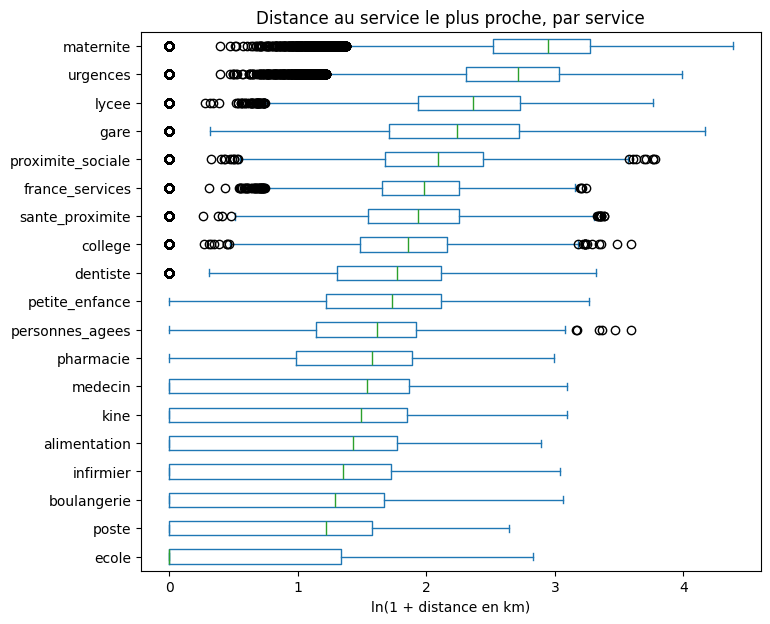

In [18]:
resume = dsc.resume_par_service(distances)
display(resume.sort_values("mediane_km", ascending=False))

ordre = distances.median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 7))
np.log1p(distances[ordre]).plot.box(vert=False, ax=ax)
ax.set_xlabel("ln(1 + distance en km)")
ax.set_title("Distance au service le plus proche, par service")
fig.savefig(FIGURES / "boites_distances.png", dpi=150, bbox_inches="tight")
plt.show()

Les services se rangent en trois groupes.

- Les services rares sont loin partout. La médiane est de 18,0 km pour la maternité, 14,0 km pour les urgences, 9,7 km pour le lycée et 8,4 km pour la gare. Pour la maternité, 1 % des communes en ont une, 10 % des communes sont à plus de 32,8 km et la plus éloignée est à 79,1 km.
- Les services du quotidien sont proches de presque tout le monde : médiane de 2,4 km pour la poste, 2,6 km pour la boulangerie et 2,9 km pour l'infirmier.
- L'école est un cas à part : 61 % des communes en ont une, donc la médiane est 0, alors que la moyenne est de 1,4 km (c'est le seul service où la moyenne est nettement au-dessus de la médiane).

Pour H1, on remarque que pour presque tous les services, la médiane et la moyenne sont très proches (3,85 et 3,79 km pour la pharmacie, 18,0 et 19,1 km pour la maternité). La distribution des distances est donc assez resserrée, sans longue queue. Le maximum vaut entre 4 et 9 fois la médiane selon le service (4,4 fois pour la maternité), l'école mise à part : il y a bien des communes très éloignées, mais elles sont peu nombreuses. L'hypothèse H1 n'est donc pas confirmée. Sur le boxplot, les points isolés à gauche pour les services rares (maternité, urgences, lycée, collège…) sont les communes qui possèdent le service : leur distance est 0, donc très loin de la boîte. Les rares points à droite (proximité sociale, France Services, santé de proximité) sont des communes particulièrement éloignées.

### 7.3 La population éloignée

Jusqu'ici on a compté des communes. Or ce qui nous intéresse vraiment, ce sont les habitants. La France compte énormément de petites communes très peu peuplées : dire que beaucoup de communes sont loin d'un service donne l'impression d'un problème massif, alors qu'elles peuvent ne regrouper qu'une petite partie de la population.

On va donc additionner la population des communes situées à plus de 5, 10 ou 20 km d'un service, et la rapporter à la population totale. Cela donne la part des habitants concernés, grâce à `dsc.part_population_eloignee`. Une commune équipée a une distance de 0, donc elle n'est jamais comptée comme éloignée.

Deux biais sont tout de même à garder en tête :

- Tous les habitants d'une commune sont supposés vivre à son centre : ils reçoivent donc la même distance au service. Dans une grande commune, certains vivent près de l'équipement et d'autres bien plus loin, et l'erreur peut aller dans les deux sens selon les communes.
- Toute la population est comptée pour chaque service, alors que tous les habitants n'ont pas besoin de tous les services : les enfants pour l'école, les femmes en âge d'avoir un enfant pour la maternité, les personnes âgées pour l'hébergement. Les pourcentages obtenus mesurent donc la population exposée à l'éloignement d'un service, et pas le nombre de personnes qui en auraient réellement besoin. Avec la population par âge et par sexe de chaque commune, on pourrait affiner ce calcul dans un prolongement du projet.

In [19]:
pop = base.set_index("code")["population"]
eloignee = dsc.part_population_eloignee(distances, pop, SEUILS_KM) # Remember seuils_km etaient les 5, 10, 20 definis en debut de ce notebook
display(eloignee.sort_values(eloignee.columns[0], ascending=False))

# Dans le tableau on lit for eg que 
# 53,07 % des habitants vivent dans une commune dont le centre est à plus de 5 km d’une maternité.
# La formule ici étant : part = (somme des populations des communes plus loin que le seuil) ÷ (population totale) × 100

,> 5 km,> 10 km,> 20 km
maternite,53.07,35.80,13.87
urgences,48.56,29.48,7.03
lycee,32.69,15.21,1.72
france_services,29.92,5.68,0.03
gare,29.91,14.24,3.59
proximite_sociale,27.46,9.26,0.50
sante_proximite,21.17,4.45,0.12
college,15.79,1.87,0.03
dentiste,10.96,1.65,0.01
petite_enfance,10.37,1.89,0.03


Ce tableau permet de faire des conclusions plus approfondies que celui qui précède. Les services rares touchent beaucoup d'habitants : 53,1 % de la population vit à plus de 5 km d'une maternité (35,8 % à plus de 10 km et 13,9 % à plus de 20 km), 48,6 % à plus de 5 km des urgences et 32,7 % à plus de 5 km d'un lycée. À l'inverse, pour les services du quotidien, très peu d'habitants sont concernés : 0,46 % pour l'école, 1,3 % pour la poste et 2,2 % pour la boulangerie à plus de 5 km.

Le seuil de 20 km distingue bien les services : seuls la maternité (13,9 %), les urgences (7,0 %), la gare (3,6 %) et le lycée (1,7 %) concernent plus de 1 % de la population à cette distance. Pour tous les autres services, personne ou presque n'est à plus de 20 km.

## 8. L'indice d'isolement

### 8.1 Principe

On dispose de 19 distances par commune, qu'on veut résumer en un seul chiffre : l'indice d'isolement. On ne peut pas additionner directement les kilomètres : un service rare comme la maternité a de grandes distances partout et écraserait un service fréquent comme l'infirmier, dont les distances sont toutes petites. Le calcul se fait en trois étapes.

1. Le logarithme : `d' = ln(1 + d)`, avec `d` en km. Il atténue les distances extrêmes avant la standardisation. Le « +1 » permet de traiter les distances nulles (service présent), car `ln(0)` n'existe pas.
2. La standardisation (z-score), service par service : `z = (d' − moyenne du service) / écart-type du service`, calculés sur l'ensemble des communes. Chaque service est ainsi ramené à la même échelle. Un `z` de +1 veut dire « un écart-type plus loin que la moyenne des communes pour ce service ». À cause de cette standardisation, l'indice mesure l'isolement relatif d'une commune par rapport aux autres communes.
3. La somme pondérée : `I = Σ(w × z) / Σ(w)`. Plus l'indice est élevé, plus la commune est isolée. On divise par la somme des poids pour garder la même échelle quel que soit le jeu de poids.

Chaque commune compte pour une unité dans le calcul de la moyenne et de l'écart-type, quelle que soit sa population.

### 8.2 Les jeux de poids

| Jeu | Définition | Question à laquelle il répond |
|---|---|---|
| `egaux` | tous les services pèsent 1 | c'est l'indice de référence |
| `vitaux` | urgences, maternité, médecin, pharmacie et santé de proximité comptent double | et si les soins de premier recours et urgents pesaient plus ? |
| `themes` | chaque thème (commerces, santé, enseignement, services publics, transport) pèse autant | et si la santé, avec ses 8 services, ne dominait pas ? |
| `acp` | première composante principale des 19 `z` | que dit la structure des données elle-même ? |

L'ACP (analyse en composantes principales) cherche la combinaison des 19 `z` qui varie le plus d'une commune à l'autre. Son signe est arbitraire, donc on l'oriente pour qu'un score élevé veuille dire « plus isolé » (on le compare à l'indice à poids égaux).

Dans le code ci-dessous, on calcule d'abord les `z` à partir des distances de référence, puis les trois premiers jeux de poids, puis l'ACP. On affiche la part de variance expliquée par la première composante, les poids de chaque jeu et un résumé de chaque indice.

In [38]:
z = idx.standardiser(idx.log_distance(distances))

poids = {
    "egaux": idx.poids_egaux(services),
    "vitaux": idx.poids_vitaux(services),
    "themes": idx.poids_themes_equilibres(services),
}
indices = pd.DataFrame({nom: idx.indice_pondere(z, p) for nom, p in poids.items()})
indices["acp"], part_pc1 = idx.indice_acp(z, indices["egaux"])

print(f"Part de la variance expliquée par la 1re composante (ACP) : {part_pc1:.1%}")
print("Tableau des poids considérés pour chaque methode")
display(pd.DataFrame(poids).round(2).T)
print("Statistiques descriptives pour les valeurs des indices trouvées suivant chaque methode")
display(indices.describe().round(3))

Part de la variance expliquée par la 1re composante (ACP) : 51.6%
Tableau des poids considérés pour chaque methode


,boulangerie,alimentation,pharmacie,medecin,dentiste,kine,infirmier,sante_proximite,urgences,maternite,ecole,college,lycee,poste,france_services,petite_enfance,personnes_agees,proximite_sociale,gare
egaux,1.0,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.0,1.0,1.0,1.0,1.0
vitaux,1.0,1.0,2.00,2.00,1.00,1.00,1.00,2.00,2.00,2.00,1.00,1.00,1.00,1.0,1.0,1.0,1.0,1.0,1.0
themes,0.5,0.5,0.12,0.12,0.12,0.12,0.12,0.12,0.12,0.12,0.33,0.33,0.33,0.2,0.2,0.2,0.2,0.2,1.0


Statistiques descriptives pour les valeurs des indices trouvées suivant chaque methode


,egaux,vitaux,themes,acp
count,34788.000,34788.000,34788.000,34788.000
mean,-0.000,-0.000,0.000,-0.000
std,0.712,0.715,0.702,3.131
min,-2.160,-2.309,-2.086,-8.968
25%,-0.414,-0.413,-0.410,-1.852
50%,0.161,0.166,0.129,0.752
75%,0.522,0.522,0.516,2.299
max,1.786,1.816,1.706,7.842


La première composante de l'ACP explique 51,6 % de la variance des 19 `z`. C'est beaucoup pour une seule composante : cela veut dire que les 19 distances évoluent ensemble, une commune éloignée d'un service a tendance à être éloignée des autres aussi. C'est ce qui justifie de résumer les 19 distances en un seul indice.

Le tableau des poids confirme la définition des jeux. Avec `themes`, chacun des 8 services de santé ne pèse plus que 0,125 (1/8), alors que la gare pèse 1 puisqu'elle est seule dans son thème. Les indices `egaux`, `vitaux` et `themes` ont une moyenne nulle et un écart-type proche de 0,7. Il est plus petit que 1 parce qu'on fait la moyenne de `z` qui sont corrélés entre eux. L'indice `acp` est sur une autre échelle (écart-type 3,1), ce qui n'est pas un problème puisqu'on ne compare que des classements.

### 8.3 Robustesse : l'indice dépend-il de nos choix ?

Notre indice repose sur des choix qu'on aurait pu faire autrement. On veut vérifier que les résultats ne changent pas beaucoup si on fait d'autres choix. On fait varier deux choses, la façon de calculer les distances et le jeu de poids.

Les trois façons de calculer les distances :

| Règle | Ce qu'elle fait | Ce qu'on teste |
|---|---|---|
| `presence` (référence) | distance 0 si la commune a le service, sinon distance du centre de la commune à l'équipement le plus proche | c'est notre règle principale |
| `sans_regle_presence` | on ne met jamais 0 : on prend toujours la distance entre le centre de la commune et l'équipement le plus proche, même s'il est dans la commune | la règle « présent = 0 » (dans une grande commune, l'équipement peut être loin du centre) |
| `positions_AB` | seules les positions de qualité A et B servent pour les distances (la présence n'est pas modifiée) | la fiabilité des coordonnées (variable `QUALITE_XY`) |

Chaque règle est combinée avec les 4 jeux de poids (`egaux`, `vitaux`, `themes`, `acp`), ce qui fait 3 × 4 = 12 indices. L'indice de référence est `presence` avec `egaux`.

On compare les indices avec la corrélation de Spearman. Elle compare les classements : on classe les communes selon chaque indice, puis on mesure la corrélation entre les classements. Elle vaut 1 si deux indices classent les communes dans le même ordre. On considère en général qu'une valeur supérieure à 0,9 indique des classements très proches.
Le code calcule les distances des deux autres règles, puis les 12 indices (dans le tableau `grille`), puis la corrélation de Spearman de chacun avec la référence, présentée en tableau règle × poids et en carte .

Distances manquantes avec A/B seulement : 0


,egaux,vitaux,themes,acp
presence,1.000,0.996,0.979,0.999
sans_regle_presence,0.963,0.960,0.940,0.964
positions_AB,0.996,0.991,0.976,0.996


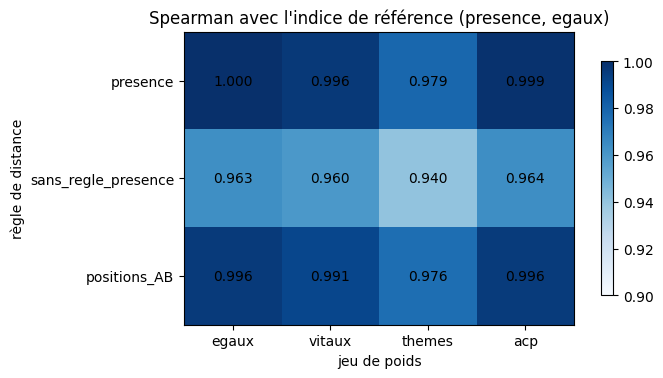

Corrélation la plus faible avec la référence : 0.940 (sans_regle_presence|themes)
Corrélation la plus faible entre deux des 12 indices : 0.928


In [21]:
# Règle 2 : positions de qualité A et B seulement (la présence n'est pas filtrée)
distances_ab, _ = dist.distances_par_service(base, equipements, services, qualites=QUALITES_FIABLES)
print("Distances manquantes avec A/B seulement :", int(distances_ab.isna().sum().sum()))

# Règle 3 : sans la règle « présent = 0 », on calcule toujours par rapport au centre de la commune
distances_sans, _ = dist.distances_par_service(base, equipements, services, regle_presence=False)

tables_distances = {
    "presence": distances,                    # la référence
    "sans_regle_presence": distances_sans,
    "positions_AB": distances_ab,
}
jeux_poids = {
    "egaux": idx.poids_egaux(services),
    "vitaux": idx.poids_vitaux(services),
    "themes": idx.poids_themes_equilibres(services),
}
NOMS_POIDS = ["egaux", "vitaux", "themes", "acp"]

# Les 12 indices : une colonne par couple (règle de distance, jeu de poids)
grille = pd.DataFrame(index=distances.index)
for regle, d in tables_distances.items():
    z_regle = idx.standardiser(idx.log_distance(d))
    for nom, p in jeux_poids.items():
        grille[f"{regle}|{nom}"] = idx.indice_pondere(z_regle, p)
    grille[f"{regle}|acp"], _ = idx.indice_acp(z_regle, grille[f"{regle}|egaux"])

# Contrôle : la colonne de référence doit être exactement l'indice calculé plus haut
assert np.allclose(grille["presence|egaux"], indices["egaux"]), "La référence ne correspond pas à l'indice du 8.2."

# Corrélation de Spearman de chacun des 12 indices avec la référence
rho_ref = grille.corr(method="spearman")["presence|egaux"]
tab_rho = pd.DataFrame(
    {nom: [rho_ref[f"{regle}|{nom}"] for regle in tables_distances] for nom in NOMS_POIDS},
    index=list(tables_distances),
)
display(tab_rho.round(3))

fig, ax = plt.subplots(figsize=(7, 3.8))
image = ax.imshow(tab_rho.values, vmin=0.9, vmax=1, cmap="Blues")
ax.set_xticks(range(len(NOMS_POIDS)))
ax.set_xticklabels(NOMS_POIDS)
ax.set_yticks(range(len(tab_rho)))
ax.set_yticklabels(tab_rho.index)
for i in range(tab_rho.shape[0]):
    for j in range(tab_rho.shape[1]):
        ax.text(j, i, f"{tab_rho.iloc[i, j]:.3f}", ha="center", va="center", color="black")
ax.set_xlabel("jeu de poids")
ax.set_ylabel("règle de distance")
ax.set_title("Spearman avec l'indice de référence (presence, egaux)")
fig.colorbar(image, shrink=0.8)
fig.savefig(FIGURES / "robustesse_spearman.png", dpi=150, bbox_inches="tight")
plt.show()

# Résumé : la corrélation la plus faible, avec la référence et entre n'importe quelles deux variantes
rho_toutes = grille.corr(method="spearman")
print(f"Corrélation la plus faible avec la référence : {rho_ref.drop('presence|egaux').min():.3f}"
      f" ({rho_ref.drop('presence|egaux').idxmin()})")
print(f"Corrélation la plus faible entre deux des 12 indices : {rho_toutes.values.min():.3f}")

# On garde les 4 indices de référence (règle presence) pour la suite, et on enregistre la grille complète
indices.reset_index().to_parquet(PROCESSED / "indices.parquet", index=False)
grille.reset_index().to_parquet(PROCESSED / "indices_robustesse.parquet", index=False)

Chaque case est la corrélation de Spearman entre l'indice de la case et l'indice de référence (`presence` avec `egaux`, en haut à gauche, qui vaut 1).

La première ligne (`presence`) ne change que le jeu de poids. `egaux` et `acp` sont presque identiques (0,999) : les poids que l'ACP trouve dans les données sont proches de poids égaux, ce qui s'accorde avec le fait qu'une seule composante explique 51,6 % de la variance. `vitaux` reste très proche (0,996) : doubler cinq services de santé et d'urgence change peu le classement. `themes` est le jeu le plus éloigné (0,979), ce qui est logique puisqu'il réduit fortement le poids de chacun des huit services de santé et augmente celui de la gare.

La colonne `egaux` ne change que la règle de distance. Ne garder que les positions de qualité A et B donne 0,996 : les coordonnées de moindre qualité ne faussent pas le classement. C'est le résultat qui nous intéresse pour la fiabilité des données, car il nous dit que le classement ne dépend pas des équipements mal localisés. La règle `sans_regle_presence` donne 0,963 : c'est le changement isolé qui modifie le plus le classement, plus que les poids. C'est cohérent, car c'est le seul qui change la définition même de la distance : une commune qui possède un service n'est plus à distance 0, mais à distance de son centre à l'équipement le plus proche.

Les cases qui combinent les deux changements restent proches elles aussi. Sur la ligne `positions_AB`, les corrélations vont de 0,976 à 0,996. Sur la ligne `sans_regle_presence`, elles vont de 0,940 à 0,964. La corrélation la plus faible avec la référence est 0,940 (`sans_regle_presence` avec `themes`), et la plus faible entre deux des 12 indices est 0,928. Toutes les valeurs sont donc supérieures à 0,9 : le classement des communes ne dépend pas beaucoup de nos choix de méthode, l'hypothèse H4 est confirmée. On garde `presence` avec `egaux` comme indice de référence, car c'est le plus simple à expliquer.

### 8.4 Distribution de l'indice et communes les plus isolées

On regarde maintenant la distribution de l'indice de référence (poids égaux). On affiche ses quantiles avec `describe`, puis son histogramme, puis la liste des 20 communes ou arrondissements à l'indice le plus élevé, avec leur population et leur surface. Un indice négatif veut dire que la commune est mieux desservie que la commune moyenne.

,indice (egaux)
count,34788.000
mean,-0.000
std,0.712
min,-2.160
1%,-1.941
10%,-1.073
25%,-0.414
50%,0.161
75%,0.522
90%,0.778


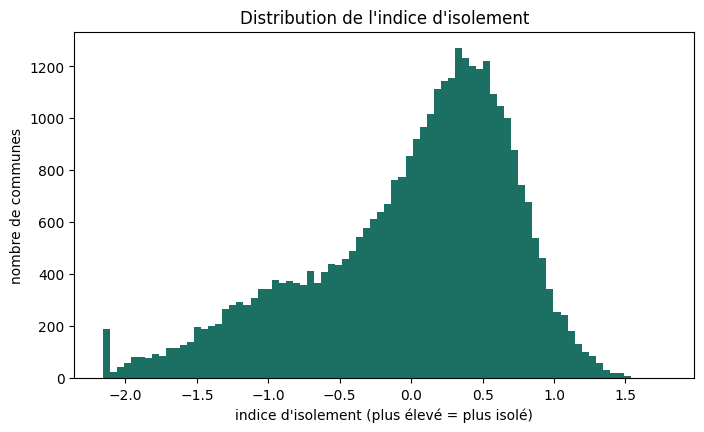

,nom,population,surface_km2,indice
code,,,,
64542,Urdos,71,36.661530,1.785700
2B153,Manso,116,121.254632,1.762382
64136,Borce,112,58.272540,1.692086
05064,La Chapelle-en-Valgaudémar,120,127.505850,1.579194
09100,Couflens,100,56.355883,1.553541
38375,Saint-Christophe-en-Oisans,99,237.506235,1.536146
21237,Échalot,93,27.665546,1.535967
64316,Larrau,179,126.986982,1.528728
51371,Moivre,54,22.175960,1.526823


In [22]:
indice = indices[INDICE_PRINCIPAL]
display(dsc.decrire_indice(indice).to_frame(f"indice ({INDICE_PRINCIPAL})"))

fig, ax = plt.subplots(figsize=(8, 4.5))
indice.plot.hist(bins=80, ax=ax, color="#1B6F63")
ax.set_xlabel("indice d'isolement (plus élevé = plus isolé)")
ax.set_ylabel("nombre de communes")
ax.set_title("Distribution de l'indice d'isolement")
fig.savefig(FIGURES / "histogramme_indice.png", dpi=150, bbox_inches="tight")
plt.show()

display(dsc.communes_les_plus_isolees(base, indice, n=20))

La distribution n'est pas symétrique : la médiane (0,16) est au-dessus de la moyenne (0), et la queue est plus longue du côté des indices négatifs (minimum de −2,16 contre un maximum de 1,79). Autrement dit, la majorité des communes sont un peu plus isolées que la moyenne, et une minorité de communes très bien desservies, les villes, tirent la moyenne vers le bas. C'est cohérent avec ce qu'on a vu à la partie 7..

Les 20 communes les plus isolées sont de très petites communes (de 5 à 179 habitants) sur de grandes surfaces, dans les Pyrénées (Urdos, Borce, Larrau), les Alpes (La Chapelle-en-Valgaudémar, Saint-Christophe-en-Oisans), en Corse (Manso, Osani, Orto), dans le Massif central, dans les Landes et dans les plaines de Champagne. C'est un profil attendu, car très peu d'habitants signifierait aussi très peu d'équipements sur place. L'indice ne dit pas en revanche que ces communes sont « mal » desservies au sens de la qualité de vie : il dit qu'elles sont, relativement aux autres, loin des 19 services.

## 9. Cartes

### 9.1 La carte de l'indice

On veut voir où se trouve l'isolement. On joint l'indice aux polygones `geo` (sur le code commune), puis on trace une carte où chaque commune est coloriée selon son indice, du clair (proche des services) au foncé (isolée). On borne l'échelle de couleurs entre les centiles 2 et 98, pour que quelques valeurs extrêmes n'écrasent pas toutes les couleurs. L'image est enregistrée dans `figures/carte_indice.png`.

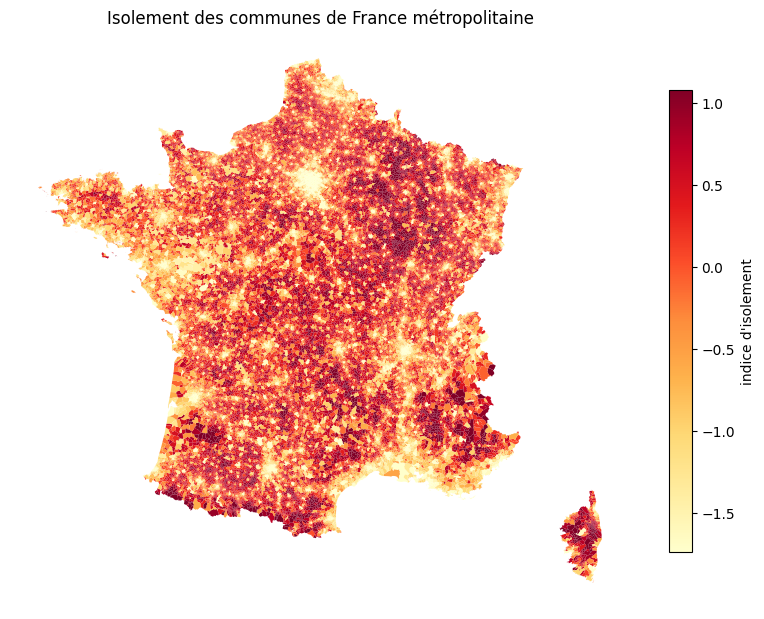

In [23]:
carte = geo.merge(indices.reset_index(), on="code")

vmin, vmax = carte[INDICE_PRINCIPAL].quantile([0.02, 0.98])
fig, ax = plt.subplots(figsize=(10, 10))
carte.plot(column=INDICE_PRINCIPAL, cmap="YlOrRd", vmin=vmin, vmax=vmax, linewidth=0, ax=ax,
           legend=True, legend_kwds={"shrink": 0.6, "label": "indice d'isolement"})
ax.set_axis_off()
ax.set_title("Isolement des communes de France métropolitaine")
fig.savefig(FIGURES / "carte_indice.png", dpi=200, bbox_inches="tight")
plt.show()

In [24]:
print("Part des communes à indice > 0 :", f"{(indice > 0).mean():.2%}")
#.mean car car on veut calculer le % et (indice > 0) va donner le nombre dont l'indice est sup à 1 vu que c'est 1 si l'indice est sup à 0 et 0 sinon et moyenne dicise par le total 
print("Médiane :", round(indice.median(), 3), "| moyenne :", round(indice.mean(), 3)) # la moyenne est proche de 0 du fait de la standardisation
pop = base.set_index("code")["population"]
print("Part de la population vivant dans une commune à indice > 0 :",
      f"{pop[indice > 0].sum() / pop.sum():.1%}")

Part des communes à indice > 0 : 59.01%
Médiane : 0.161 | moyenne : -0.0
Part de la population vivant dans une commune à indice > 0 : 9.9%


59 % des communes ont un indice supérieur à 0, c'est-à-dire qu'elles sont plus isolées que la commune moyenne. Mais elles ne regroupent que 9,9 % de la population : les communes isolées sont nombreuses mais peu peuplées, alors que les 41 % de communes mieux desservies (les villes et leurs environs) regroupent 90 % des habitants.

Sur la carte, les communes les plus foncées forment de grandes zones. On voit les Alpes, les Pyrénées, la Corse, le sud-ouest (Landes), le Massif central et une large bande qui va de la Champagne à la Bourgogne. À l'inverse, les points clairs sont les grandes villes (Paris, Lyon, Bordeaux, Toulouse, Marseille…) et leurs environs, ainsi que le littoral atlantique et la Bretagne, mieux desservis. On n'a pas fait de test statistique pour ce regroupement donc cette lecture reste purement visuelle.

### 9.2 Les cartes par service

L'indice résume 19 services, mais deux communes de même indice peuvent manquer de services très différents. On regarde donc quel service manque, et où. Pour les six services de `SERVICES_CARTES`, on trace une nouvelle carte de `ln(1 + distance)`. Chaque carte a sa propre échelle de couleurs, bornée au 98ᵉ centile, car les distances d'une gare et d'une boulangerie n'ont pas la même ampleur. L'image est enregistrée dans `figures/cartes_services.png`.

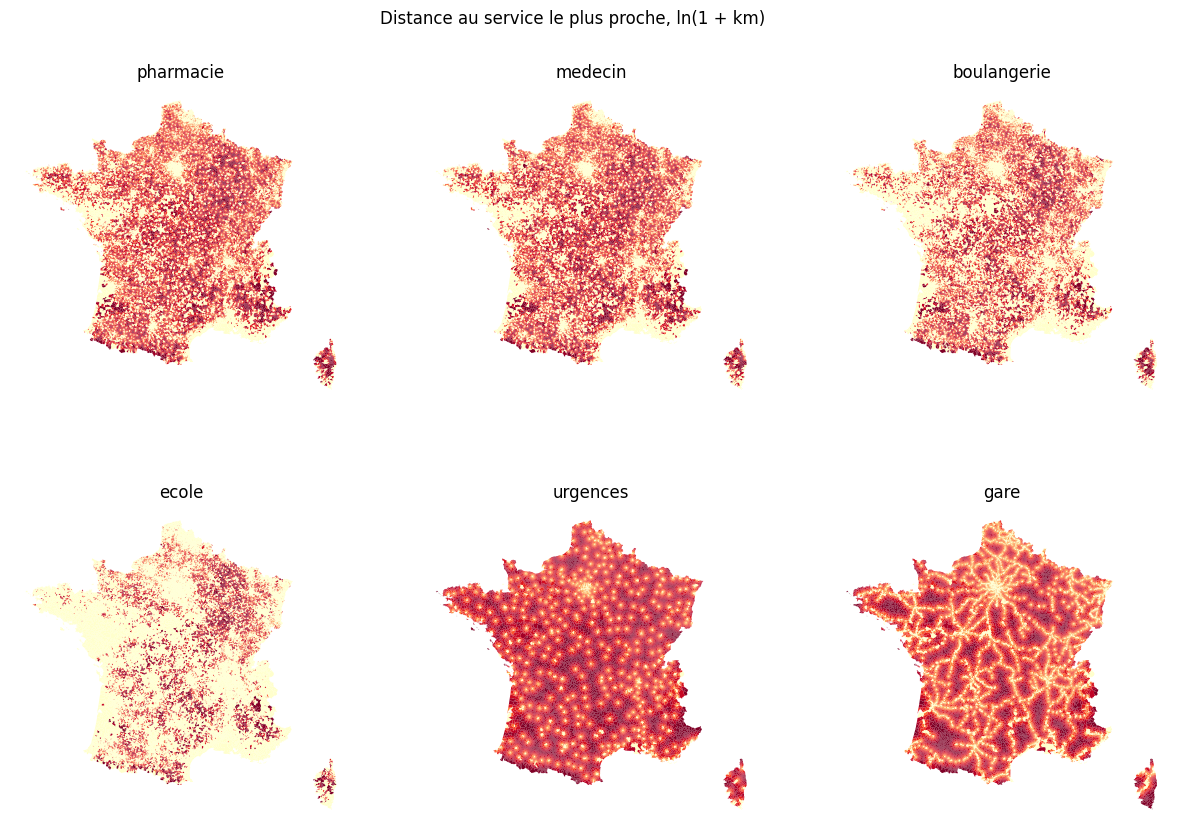

In [25]:
carte_services = geo.merge(distances.reset_index(), on="code")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, service in zip(axes.ravel(), SERVICES_CARTES):
    valeurs = np.log1p(carte_services[service])
    carte_services.assign(valeur=valeurs).plot(
        column="valeur", cmap="YlOrRd", vmin=0, vmax=float(valeurs.quantile(0.98)),
        linewidth=0, ax=ax, legend=False)
    ax.set_axis_off()
    ax.set_title(service)
fig.suptitle("Distance au service le plus proche, ln(1 + km)", y=0.94)
fig.savefig(FIGURES / "cartes_services.png", dpi=150, bbox_inches="tight")
plt.show()

Les cartes ne se ressemblent pas, ce qui est cohérent avec les médianes de la partie 7.2. Pour la pharmacie, le médecin et la boulangerie, la plupart des communes sont proches et seules les zones de montagne (Alpes, Pyrénées, Corse) et les campagnes du centre ressortent. Pour l'école, presque tout le territoire est clair (la médiane est à 0). Pour les urgences et la gare, c'est l'inverse : presque tout le territoire est foncé et seules les villes ressortent en clair. Sur la carte des gares, on voit même le réseau ferré : les zones claires s'allongent le long des lignes qui partent de Paris. C'est pour cela que l'indice a besoin des 19 services : un seul service ne suffirait pas à décrire l'isolement.

## 10. Isolement et densité (hypothèse H2)

On teste ici l'hypothèse suivante : plus une commune est peu dense, plus elle est isolée.

On utilise la corrélation de Spearman (et pas celle de Pearson). Pearson mesure une relation entre les valeurs, et comme la densité est très asymétrique, quelques communes très denses écraseraient tout. Spearman remplace chaque valeur par son rang (la 1ʳᵉ, la 2ᵉ, la 3ᵉ…) puis calcule la corrélation des rangs. Elle vaut −1 (sens opposés), 0 (aucun lien) ou +1 (même ordre).

On part de `indice` (poids égaux, une valeur par commune) et de la colonne `densite` de `base` (habitants par km²). Le code charge le module `analyse` et aligne les deux séries sur les mêmes codes commune. Il calcule ensuite le Spearman sur les communes qui ont une densité. La p-value donne la probabilité d'observer un lien aussi fort par hasard, mais avec 34 000 communes elle sera minuscule pour presque n'importe quel lien : c'est donc la valeur de ρ qui compte plus que la p-value.

Ensuite on range les communes en 5 classes de densité de même effectif (les quintiles : les 20 % de communes les moins denses, etc.) et on compare l'indice entre les classes avec le test de Kruskal-Wallis. Ce test regarde si l'indice est distribué de la même façon dans tous les groupes. On regarde aussi sa taille d'effet ε², entre 0 et 1, qui dit si l'écart est grand (un ε² de 0,3 voudrait dire que la densité explique environ 30 % de la variation des rangs de l'indice).

Enfin on trace deux graphiques : un nuage de points (log de la densité en abscisse, indice en ordonnée, en version hexbin car il y a trop de points) et des boîtes à moustaches par classe de densité.

Spearman indice / densité : rho = -0.843  (n = 34,788, p = 0)
Kruskal-Wallis : H = 23639, p = 0, taille d'effet epsilon2 = 0.680


,communes,mediane,q25,q75
g,,,,
1 ( les 20% les moins dense),6958,0.718,0.532,0.897
2,6957,0.431,0.241,0.602
3,6958,0.187,-0.052,0.375
4,6957,-0.156,-0.497,0.085
5 (les 20% les plus dense),6958,-0.978,-1.364,-0.561


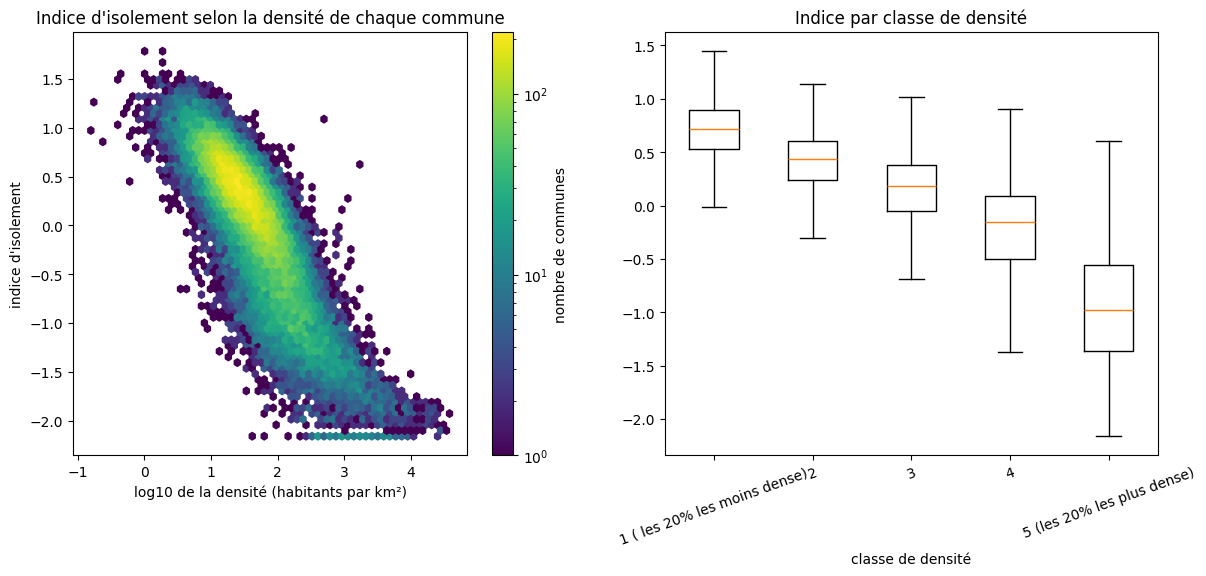

In [26]:
import analyse as an

dens = base.set_index("code")["densite"]
indice_a = indice.reindex(dens.index)

res_dens = an.correlation_spearman(indice_a, dens)
print(f"Spearman indice / densité : rho = {res_dens['rho']:.3f}  (n = {res_dens['n']:,}, p = {res_dens['p_value']:.2g})")

NOMS_DENSITE = ["1 ( les 20% les moins dense)", "2", "3", "4", "5 (les 20% les plus dense)"]
classe_densite = pd.qcut(dens.rank(method="first"), 5, labels=NOMS_DENSITE)
res_kw, tab_dens = an.comparer_groupes(indice_a, classe_densite)
print(f"Kruskal-Wallis : H = {res_kw['H']:.0f}, p = {res_kw['p_value']:.2g}, taille d'effet epsilon2 = {res_kw['epsilon2']:.3f}")
display(tab_dens)

ok = dens.notna() & (dens > 0)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
hb = axes[0].hexbin(np.log10(dens[ok]), indice_a[ok], gridsize=60, bins="log", cmap="viridis", mincnt=1)
axes[0].set_xlabel("log10 de la densité (habitants par km²)")
axes[0].set_ylabel("indice d'isolement")
axes[0].set_title("Indice d'isolement selon la densité de chaque commune")
fig.colorbar(hb, ax=axes[0], label="nombre de communes")
groupes_d = [indice_a[classe_densite == c].dropna() for c in NOMS_DENSITE]
axes[1].boxplot(groupes_d, showfliers=False)
axes[1].set_xticks(range(1, len(NOMS_DENSITE) + 1))
axes[1].set_xticklabels(NOMS_DENSITE)
axes[1].set_xlabel("classe de densité")
axes[1].set_title("Indice par classe de densité")
axes[1].tick_params(axis="x", rotation=20)
fig.savefig(FIGURES / "densite_indice.png", dpi=150, bbox_inches="tight")
plt.show()

On obtient ρ = −0,84 sur 34 788 communes. Plus la densité est faible, plus l'indice est élevé. Le test de Kruskal-Wallis le confirme (ε² = 0,68), ce qui est un effet très fort : la densité seule explique à peu près les deux tiers de la variation des rangs de l'indice.

Le tableau par classe montre la progression. L'indice médian passe de 0,72 pour les 20 % de communes les moins denses à 0,43, 0,19, −0,16, puis −0,98 pour les 20 % les plus denses. La baisse est régulière sur les cinq classes, et c'est dans la classe la plus dense qu'elle est la plus forte. L'hypothèse H2 est donc confirmée.

Ce résultat est logique : un service s'installe là où il y a assez d'habitants pour le faire vivre, donc les communes peu denses en ont moins sur place et doivent aller les chercher plus loin. Toutefois, ce lien reste une corrélation, et donc il ne prouve pas que la faible densité est la cause de l'isolement.


## 11. Isolement et revenu (hypothèse H3)

### 11.1 Ajouter le revenu médian

On va chercher le niveau de vie médian de chaque commune (indicateur `MED_SL` de Filosofi 2023). Le fichier est en format long ( une ligne par couple (territoire, indicateur), avec tous les niveaux géographiques mélangés). Il contient plusieurs centaines de milliers de lignes, dont la plupart n'ont pas de valeur : ce sont des indicateurs non publiés à l'échelle communale (pour une petite commune, publier la valeur permettrait de deviner les revenus des habitants, donc le secret statistique impose de ne pas la publier, elle est donc anonymisée). Il faut donc filtrer sur les communes et les arrondissements qui nous intéressent.

Pour cela, `an.lire_revenu` garde seulement les lignes dont le type de territoire est une commune (`COM`) ou un arrondissement (`ARM`), et l'indicateur `MED_SL`. Les valeurs absentes (secret statistique `s`, donnée manquante `vm`) deviennent des cases vides, et les codes sont remis sur 5 caractères. Ensuite `an.fusionner_revenu` joint le revenu à la base par une jointure à gauche : aucune commune de la base ne disparaît, celles sans revenu restent avec une case vide. Un journal compte les communes sans revenu et les codes du fichier qui ne sont pas dans la base.

In [27]:
FICHIER_REVENU = RAW / "Revenus.csv"

revenu = an.lire_revenu(FICHIER_REVENU)
base_rev, journal_rev = an.fusionner_revenu(base, revenu)
print("Journal de la fusion du revenu :", journal_rev)
print(f"Part des communes sans revenu : {journal_rev['communes_sans_revenu'] / journal_rev['communes_base']:.1%}")

revenu_s = base_rev.set_index("code")["revenu_median"]
display(revenu_s.describe().round(0).to_frame("niveau de vie médian (€)"))

Journal de la fusion du revenu : {'communes_base': 34788, 'communes_sans_revenu': 3976, 'codes_revenu_hors_base': 27}
Part des communes sans revenu : 11.4%


,niveau de vie médian (€)
count,30812.0
mean,26270.0
std,3541.0
min,12420.0
25%,24090.0
50%,25780.0
75%,27840.0
max,62730.0


On a un revenu pour 30 812 communes sur 34 788. La médiane des niveaux de vie communaux est de 25 780 € (moyenne 26 270 €), avec un écart-type de 3 541 € : la plupart des communes se situent entre 24 090 € et 27 840 € (premier et troisième quartiles), et quelques communes très aisées tirent le maximum à 62 730 €. 3 976 communes (11,4 %) n'ont pas de revenu publié.

### 11.2 Les communes sans revenu sont-elles différentes ?

On veut vérifier si les valeurs manquantes créent un biais. À cause du secret statistique, on ne connaît pas le revenu des petites communes, qui sont souvent isolées : si on les écarte, on risque de sous-estimer le lien entre isolement et revenu.

On sépare donc les communes en deux groupes (avec revenu, sans revenu), on compare l'indice d'isolement de chaque groupe avec le test de Kruskal-Wallis (ici entre deux groupes), puis on calcule la part de la population concernée.

In [28]:
a_revenu = pd.Series(np.where(revenu_s.notna(), "avec revenu", "sans revenu"), index=revenu_s.index)

res_man, tab_man = an.comparer_groupes(indice.reindex(a_revenu.index), a_revenu)
print(f"Kruskal-Wallis (indice, avec/sans revenu) : p = {res_man['p_value']:.2g}, epsilon2 = {res_man['epsilon2']:.3f}")
display(tab_man)

pop_s = base.set_index("code")["population"]
print(f"Part de la population dans les communes sans revenu : "
      f"{pop_s[a_revenu == 'sans revenu'].sum() / pop_s.sum():.2%}")

Kruskal-Wallis (indice, avec/sans revenu) : p = 0, epsilon2 = 0.164


,communes,mediane,q25,q75
g,,,,
avec revenu,30812,0.070,-0.524,0.428
sans revenu,3976,0.718,0.513,0.912


Part de la population dans les communes sans revenu : 0.44%


Les 3 976 communes sans revenu médian publié (11,4 %) sont nettement plus isolées que les autres : indice médian de 0,72 contre 0,07 (test de Kruskal-Wallis, p < 0,001, ε² = 0,16, effet fort). Elles ne regroupent en revanche que 0,44 % de la population. L'analyse du revenu porte donc sur un échantillon moins isolé que l'ensemble des communes, et ses conclusions ne s'appliquent pas aux communes les plus isolées.

### 11.3 Le lien entre isolement et revenu

On veut mesurer si les communes plus isolées sont plus pauvres (ou plus riches), et si l'effet est grand. On calcule d'abord le Spearman entre l'indice et le revenu médian, sur les communes qui ont un revenu. Ensuite on les répartit en 5 quintiles de revenu (5 groupes de même effectif, du revenu le plus bas au plus haut), et on applique le test de Kruskal-Wallis et sa taille d'effet ε² (voir la partie 10), avec l'indice médian de chaque groupe. Enfin on trace un diagramme en boîtes de l'indice par quintile de revenu.

Un ρ négatif voudrait dire « plus isolé, plus pauvre », et un ρ positif « plus isolé, plus riche ». Aussi corrélation n'est pas causalité (et donc elle dit que les deux vont ensemble, pas que l'un provoque l'autre.)

Spearman indice / revenu : rho = -0.216  (n = 30,812, p = 0)
Kruskal-Wallis : H = 1554, p = 0, epsilon2 = 0.050


,communes,mediane,q25,q75
g,,,,
1 (plus bas),6163,0.285,-0.576,0.621
2,6162,0.202,-0.343,0.491
3,6162,0.132,-0.328,0.431
4,6162,0.010,-0.494,0.337
5 (plus haut),6163,-0.233,-0.782,0.147


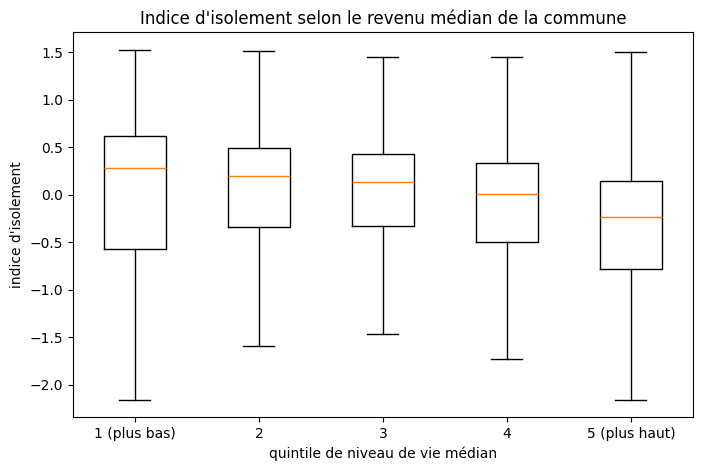

In [29]:
indice_r = indice.reindex(revenu_s.index)

res_rev = an.correlation_spearman(indice_r, revenu_s)
print(f"Spearman indice / revenu : rho = {res_rev['rho']:.3f}  (n = {res_rev['n']:,}, p = {res_rev['p_value']:.2g})")

NOMS_REVENU = ["1 (plus bas)", "2", "3", "4", "5 (plus haut)"]
quintile_revenu = pd.qcut(revenu_s.rank(method="first"), 5, labels=NOMS_REVENU)
res_kw_rev, tab_rev = an.comparer_groupes(indice_r, quintile_revenu)
print(f"Kruskal-Wallis : H = {res_kw_rev['H']:.0f}, p = {res_kw_rev['p_value']:.2g}, epsilon2 = {res_kw_rev['epsilon2']:.3f}")
display(tab_rev)

fig, ax = plt.subplots(figsize=(8, 5))
groupes = [indice_r[quintile_revenu == q].dropna() for q in NOMS_REVENU]
ax.boxplot(groupes, showfliers=False)
ax.set_xticks(range(1, len(NOMS_REVENU) + 1))
ax.set_xticklabels(NOMS_REVENU)
ax.set_xlabel("quintile de niveau de vie médian")
ax.set_ylabel("indice d'isolement")
ax.set_title("Indice d'isolement selon le revenu médian de la commune")
fig.savefig(FIGURES / "revenu_indice.png", dpi=150, bbox_inches="tight")
plt.show()

Plus le niveau de vie médian de la commune est élevé, moins elle tend à être isolée. Les communes les plus modestes sont un peu plus isolées que la moyenne (indice médian positif), les plus aisées sont mieux desservies (indice médian négatif).

L'écart s'accentue en haut de l'échelle : les écarts entre quintiles successifs sont de 0,08, 0,07, 0,12 puis 0,24. C'est surtout le cinquième des communes les plus aisées qui se détache.

L'effet reste modeste. Entre le premier et le dernier quintile, la médiane passe de 0,29 à −0,23, soit environ 0,5 point d'indice. Mais les boîtes se chevauchent largement : dans chaque quintile on trouve des communes très isolées et des communes très bien desservies, avec des moustaches presque identiques (de −2 à +1,5). Cela rejoint le ρ de Spearman de −0,22 et l'ε² de 0,05, qui indiquent un lien faible à moyen. Le revenu ne permet pas de prédire l'isolement d'une commune donnée.


### 11.4 Effet de la densité

On veut vérifier que le lien entre isolement et revenu n'est pas simplement un effet de la densité. La densité est liée à l'isolement (partie 10) et aussi au revenu (les villes n'ont pas les mêmes revenus médians que les campagnes). Une variable qui influence les deux à la fois peut créer un lien apparent entre elles (facteur de confusion).

On calcule d'abord la corrélation de Spearman entre le revenu et la densité. Ensuite on refait la corrélation entre l'indice et le revenu séparément dans chacune des 5 classes de densité. Dans chaque classe la densité varie peu et donc si le lien persiste, il ne vient pas seulement de la densité. Si ρ va vers 0 dans les classes, c'est que le lien global était surtout dû à la densité. S'il garde le même signe et une taille comparable, l'isolement a un lien propre avec le revenu.

In [30]:
res_rev_dens = an.correlation_spearman(revenu_s, dens.reindex(revenu_s.index))
print(f"Spearman revenu / densité : rho = {res_rev_dens['rho']:.3f}  (n = {res_rev_dens['n']:,})")

classe_d = classe_densite.reindex(revenu_s.index)
lignes = {c: an.correlation_spearman(indice_r[classe_d == c], revenu_s[classe_d == c]) for c in NOMS_DENSITE}
print("\nCorrélation indice / revenu à l'intérieur de chaque classe de densité :")
display(pd.DataFrame(lignes).T.round(3))

Spearman revenu / densité : rho = 0.347  (n = 30,812)

Corrélation indice / revenu à l'intérieur de chaque classe de densité :


,rho,p_value,n
1 ( les 20% les moins dense),-0.071,0.000,3968.0
2,0.006,0.663,6172.0
3,0.052,0.000,6790.0
4,0.153,0.000,6928.0
5 (les 20% les plus dense),0.294,0.000,6954.0


Le revenu et la densité sont liés (ρ = 0,35), donc la densité peut bien jouer le rôle de facteur de confusion. Quand on refait la corrélation à l'intérieur de chaque classe de densité, le lien négatif du début disparaît : ρ vaut −0,07 dans la classe la moins dense, puis 0,01, 0,05, 0,15 et 0,29 dans la plus dense. Le lien global entre isolement et revenu (ρ = −0,22) est donc surtout un effet de la densité : les territoires peu denses sont à la fois plus isolés et plus modestes.

À densité comparable, le lien est proche de 0 dans les zones rurales et il devient même positif dans les zones denses : dans les communes les plus denses, ce sont les plus aisées qui ont tendance à être un peu plus éloignées des services. On peut penser à des communes résidentielles de périphérie, mais nous ne l'avons pas vérifié. L'hypothèse H3 n'est donc que partiellement confirmée : il y a un lien global faible, qui vient surtout de la densité, et dont le signe change selon le type de territoire.

### 11.5 Les corrélations selon la méthode de calcul

Les corrélations avec la densité et avec le revenu ont été calculées avec l'indice de référence. On refait le calcul avec les 12 indices de la partie 8.3, pour vérifier que ces résultats ne dépendent pas de la règle de distance ni du jeu de poids. Pour chaque indice, on calcule le ρ de Spearman avec la densité et avec le revenu, qu'on présente en tableau règle × poids.

In [31]:
resultats = {}
for nom in grille.columns:
    r_dens = an.correlation_spearman(grille[nom].reindex(dens.index), dens)
    r_rev = an.correlation_spearman(grille[nom].reindex(revenu_s.index), revenu_s)
    resultats[tuple(nom.split("|"))] = {"densité": r_dens["rho"], "revenu": r_rev["rho"]}
resultats = pd.DataFrame(resultats).T
resultats.index.names = ["règle", "poids"]

for libelle, variable in [("la densité", "densité"), ("le revenu", "revenu")]:
    print(f"Spearman entre l'indice et {libelle}, selon la règle de distance et le jeu de poids :")
    display(resultats[variable].unstack("poids")[NOMS_POIDS].loc[list(tables_distances)].round(3))

Spearman entre l'indice et la densité, selon la règle de distance et le jeu de poids :


poids,egaux,vitaux,themes,acp
règle,,,,
presence,-0.843,-0.843,-0.836,-0.839
sans_regle_presence,-0.861,-0.858,-0.855,-0.859
positions_AB,-0.846,-0.846,-0.838,-0.842


Spearman entre l'indice et le revenu, selon la règle de distance et le jeu de poids :


poids,egaux,vitaux,themes,acp
règle,,,,
presence,-0.216,-0.232,-0.221,-0.209
sans_regle_presence,-0.276,-0.287,-0.286,-0.269
positions_AB,-0.223,-0.240,-0.226,-0.215


Il en ressort que les conclusions des parties 10 et 11 tiennent quelle que soit la méthode.

Pour la densité, ρ reste fortement négatif dans les 12 cas, entre −0,84 et −0,86 (H2). Le jeu de poids ne change presque rien : sur la ligne `presence`, ρ va de −0,836 à −0,843. La règle de distance joue un peu plus. Sans la règle « présent = 0 », le lien est un peu plus fort (−0,86), ce qui est logique : ne plus mettre 0 pour les communes équipées, c'est-à-dire surtout les villes denses, creuse l'écart avec les communes rurales.

Pour le revenu, ρ reste négatif et faible dans les 12 cas, entre −0,21 et −0,29 (H3). Là aussi, c'est la règle de distance qui fait le plus varier le résultat : sur la ligne `sans_regle_presence`, ρ est entre −0,27 et −0,29, contre −0,21 à −0,23 sur la ligne `presence`. Le lien est un peu plus marqué, mais il reste faible, et le signe ne change dans aucun cas. La case `presence` avec `egaux` retrouve bien les valeurs des parties 10 et 11 (−0,843 et −0,216).

Nos conclusions sur la densité et sur le revenu ne dépendent donc pas du choix de la règle de distance ni du jeu de poids.

## 12. Typologie : quels types d'isolement ?

L'indice dit à quel point une commune est isolée, pas de quoi. Deux communes de même indice peuvent manquer de services très différents. On cherche donc des profils types : des groupes de communes qui se ressemblent par la manière dont elles sont éloignées des services.

On part des 19 écarts standardisés `z` de chaque commune (partie 8). Le k-means forme `k` groupes en répétant deux étapes : rattacher chaque commune au centre de groupe le plus proche, puis recalculer chaque centre comme la moyenne de son groupe. Il faut fixer `k` à l'avance. Pour le choisir, on regarde deux indicateurs :

- l'inertie (somme des carrés des écarts aux centres) baisse toujours quand `k` augmente, donc on cherche le « coude » où elle cesse de baisser vite ;
- la silhouette (de −1 à 1) dit si les groupes sont bien séparés : plus elle est haute, mieux c'est.

On choisit `k` par jugement, entre 4 et 6 pour rester lisible, en s'aidant de ces deux courbes.

Dans le code, `an.choisir_k` calcule l'inertie et la silhouette pour `k` de 2 à 8, sur un échantillon de 5 000 communes pour aller vite, et on les trace. Ensuite on fixe `N_GROUPES` et `an.typologie` lance le k-means et numérote les groupes du mieux desservi (0) au moins bien desservi (la numérotation brute du k-means est aléatoire). Elle calcule aussi le plan des deux premières composantes principales (PC1 et PC2) pour dessiner les groupes. On calcule le profil moyen de chaque groupe (la moyenne des `z` de chaque service) qu'on affiche en carte de chaleur : rouge pour plus éloigné que la moyenne, bleu pour plus proche. Un tableau résume chaque groupe (nombre de communes, part de la population, indice, densité et revenu médians), et une carte colorie chaque commune selon son groupe.

In [32]:
%pip install --upgrade threadpoolctl

Note: you may need to restart the kernel to use updated packages.
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.7.0
    Uninstalling threadpoolctl-3.7.0:
      Successfully uninstalled threadpoolctl-3.7.0


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
shap 0.50.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.


,inertie,silhouette
k,,
2,417308.307,0.370
3,363680.821,0.198
4,333254.171,0.162
5,316938.006,0.146
6,301811.276,0.141
7,289395.890,0.145
8,278675.412,0.112


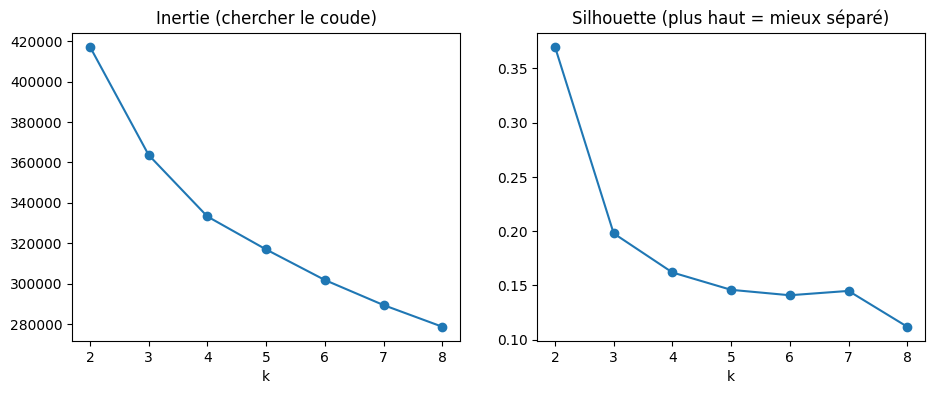

In [33]:
cout_k = an.choisir_k(z)
display(cout_k)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cout_k["inertie"].plot(marker="o", ax=axes[0], title="Inertie (chercher le coude)")
cout_k["silhouette"].plot(marker="o", ax=axes[1], title="Silhouette (plus haut = mieux séparé)")
fig.savefig(FIGURES / "choix_k.png", dpi=150, bbox_inches="tight")
plt.show()

L'inertie baisse sans coude net, et la silhouette est la plus haute pour `k = 2` (0,37) puis baisse (0,16 pour `k = 4`, 0,14 pour `k = 6`). Cela veut dire que les communes ne forment pas des groupes bien séparés et elles s'étalent plutôt sur un continuum, des villes aux communes rurales isolées. Avec `k = 2`, on aurait seulement « urbain » contre « rural ». On retient `k = 4`, mais les frontières entre groupes sont un peu arbitraires.

Variance expliquée par PC1 et PC2 : [0.516 0.093]


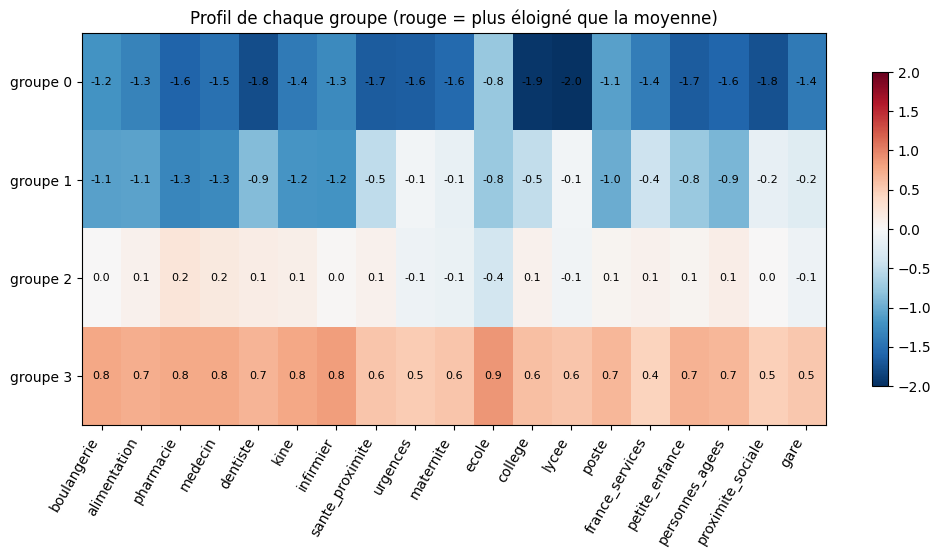

,communes,part_population_%,indice_median,densite_mediane,revenu_median
groupe,,,,,
0,3030,63.7,-1.45,541.7,25995.0
1,6145,20.5,-0.72,112.9,25980.0
2,12576,11.6,0.07,50.9,26390.0
3,13037,4.3,0.62,15.8,24910.0


In [34]:
N_GROUPES = 4       
res_typo, profils, var_pca = an.typologie(z, N_GROUPES)
print(f"Variance expliquée par PC1 et PC2 : {var_pca.round(3)}")

# Profils : moyenne des z de chaque service dans chaque groupe
fig, ax = plt.subplots(figsize=(12, 3.5 + 0.4 * N_GROUPES))
im = ax.imshow(profils, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(profils.shape[1]))
ax.set_xticklabels(profils.columns, rotation=60, ha="right")
ax.set_yticks(range(N_GROUPES))
ax.set_yticklabels([f"groupe {g}" for g in profils.index])
for i in range(profils.shape[0]):
    for j in range(profils.shape[1]):
        ax.text(j, i, f"{profils.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.set_title("Profil de chaque groupe (rouge = plus éloigné que la moyenne)")
fig.colorbar(im, shrink=0.8)
fig.savefig(FIGURES / "profils_groupes.png", dpi=150, bbox_inches="tight")
plt.show()

# Résumé par groupe
g = res_typo["groupe"]
resume_groupes = pd.DataFrame({
    "communes": g.value_counts().sort_index(),
    "part_population_%": (pop_s.groupby(g).sum() / pop_s.sum() * 100).round(1),
    "indice_median": indice.groupby(g).median().round(2),
    "densite_mediane": dens.groupby(g).median().round(1),
    "revenu_median": revenu_s.groupby(g).median().round(0),
})
display(resume_groupes)

Les deux premières composantes expliquent 51,6 % et 9,3 % de la variance des `z`. La PC1 est la composante de l'ACP de la partie 8 : c'est l'axe « proche ou loin de tous les services ». La PC2 apporte beaucoup moins (9,3 %).

Le tableau montec des groupes de tailles très inégaleshab/km² |

Le groupe 0 ne représente que 9 % des communes mais près de 64 % des habitants. À l'opposé, le groupe 3 compte plus du tiers des communes (37 %) mais seulement 4,3 % de la population. Le revenu médian est presque le même dans les groupes 0, 1 et 2 (entre 25 980 € et 26 390 €) et un peu plus bas dans le groupe 3 (24 910 €), ce qui rejoint le lien faible entre isolement et revenu de la partie 11.

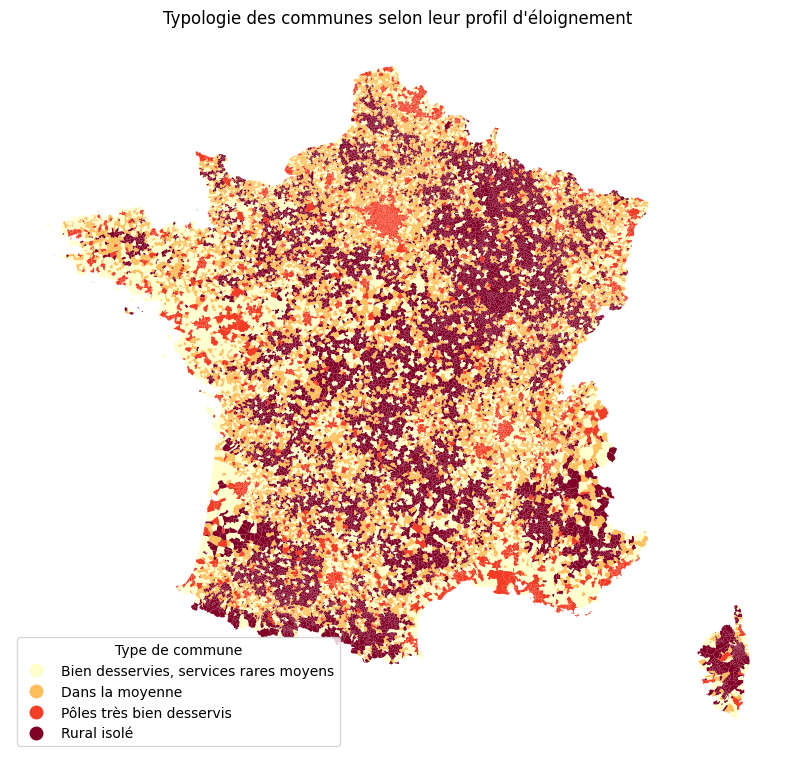

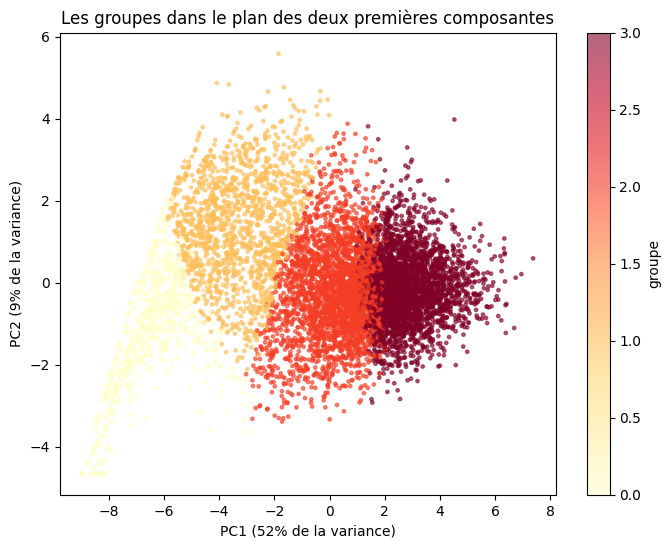

In [35]:
NOMS_GROUPES = {0: "Pôles très bien desservis", 1: "Bien desservies, services rares moyens",
                2: "Dans la moyenne", 3: "Rural isolé"}

carte_typo = geo.merge(res_typo.rename_axis("code").reset_index(), on="code")
carte_typo["type"] = carte_typo["groupe"].map(NOMS_GROUPES)

fig, ax = plt.subplots(figsize=(10, 10))
carte_typo.plot(column="type", categorical=True, cmap="YlOrRd", linewidth=0, ax=ax, legend=True,
                legend_kwds={"loc": "lower left", "title": "Type de commune"})
ax.set_axis_off()
ax.set_title("Typologie des communes selon leur profil d'éloignement")
fig.savefig(FIGURES / "carte_typologie.png", dpi=200, bbox_inches="tight")
plt.show()

# Plan PC1 x PC2 (échantillon de 8 000 communes pour la lisibilité)
echantillon = res_typo.sample(min(8000, len(res_typo)), random_state=0)
fig, ax = plt.subplots(figsize=(8, 6))
nuage = ax.scatter(echantillon["pc1"], echantillon["pc2"], c=echantillon["groupe"], cmap="YlOrRd", s=6, alpha=0.6)
ax.set_xlabel(f"PC1 ({var_pca[0]:.0%} de la variance)")
ax.set_ylabel(f"PC2 ({var_pca[1]:.0%} de la variance)")
ax.set_title("Les groupes dans le plan des deux premières composantes")
fig.colorbar(nuage, label="groupe")
fig.savefig(FIGURES / "plan_acp.png", dpi=150, bbox_inches="tight")
plt.show()

Le profil des groupes confirme les noms donnés. Le groupe 0 est proche de tous les services (de −1,1 à −2,0 selon le service). Le groupe 1 est très proche des services du quotidien (boulangerie, pharmacie, médecin, de −1,1 à −1,3), mais plutôt dans la moyenne pour les services rares (urgences, maternité, lycée, gare, autour de −0,1 à −0,2). Le groupe 2 est dans la moyenne partout. Le groupe 3 est éloigné de tout (de +0,4 à +0,9), et surtout de l'école (+0,9).

Sur le plan PC1 × PC2, les groupes s'ordonnent bien le long de PC1, du groupe 0 à gauche au groupe 3 à droite : ils se distinguent d'abord par leur niveau global d'éloignement. La PC2 sépare surtout le groupe 1 (en haut) du groupe 0 (en bas) : c'est l'opposition entre services du quotidien et services rares.

La carte montre que les pôles très bien desservis (groupe 0) sont les grandes villes, comme l'agglomération parisienne ou Montpellier. Les communes « bien desservies, services rares moyens » (groupe 1) se concentrent sur la façade atlantique et en Bretagne. Le « rural isolé » (groupe 3) forme de grandes zones continues : la Champagne et la Bourgogne, le Massif central, le sud-ouest, les Pyrénées, les Alpes et la Corse.

## 13. Table finale de l'analyse

On rassemble dans le fichier final: l'indice, son rang en centile, le groupe de la typologie, la population, la densité et le revenu. Le centile de l'indice est plus parlant qu'un `z` positif ou négatif : un centile de 90 veut dire que la commune est plus isolée que 90 % des communes, donc qu'elle fait partie des 10 % les plus isolées. On enregistre le tout dans `data/processed/communes_analyse.parquet`. 

In [36]:
final = base.set_index("code")[["nom", "population", "surface_km2", "densite"]].copy()
final["revenu_median"] = revenu_s
final["indice"] = indice
final["indice_centile"] = (indice.rank(pct=True) * 100).round(1)
final["groupe"] = res_typo["groupe"]

final.reset_index().to_parquet(PROCESSED / "communes_analyse.parquet", index=False)
print(f"Enregistré : {final.shape[0]:,} communes, {final.shape[1]} colonnes")
display(final.sort_values("indice", ascending=False).head(10))

Enregistré : 34,788 communes, 8 colonnes


,nom,population,surface_km2,densite,revenu_median,indice,indice_centile,groupe
code,,,,,,,,
64542,Urdos,71,36.661530,1.936635,NaN,1.785700,100.0,3
2B153,Manso,116,121.254632,0.956664,NaN,1.762382,100.0,3
64136,Borce,112,58.272540,1.922003,NaN,1.692086,100.0,3
05064,La Chapelle-en-Valgaudémar,120,127.505850,0.941133,NaN,1.579194,100.0,3
09100,Couflens,100,56.355883,1.774438,NaN,1.553541,100.0,3
38375,Saint-Christophe-en-Oisans,99,237.506235,0.416831,NaN,1.536146,100.0,3
21237,Échalot,93,27.665546,3.361582,NaN,1.535967,100.0,3
64316,Larrau,179,126.986982,1.409593,20970.0,1.528728,100.0,3
51371,Moivre,54,22.175960,2.435069,NaN,1.526823,100.0,3


## 14. Conclusion

### 14.1 Ce qu'on a fait

On a mesuré, pour les 34 788 communes et arrondissements de France métropolitaine (66,2 millions d'habitants), la distance à 19 services de base, construits à partir de 531 417 équipements de la BPE 2025. On a résumé ces 19 distances dans un indice d'isolement, puis on a vérifié qu'il ne dépendait pas beaucoup de nos choix : 3 règles de distance et 4 jeux de poids, soit 12 indices. Enfin on a décrit l'isolement, on l'a cartographié et on l'a relié à la densité et au revenu.

### 14.2 Les hypothèses

| Hypothèse | Ce qu'on observe | Où le lire | Verdict |
|---|---|---|---|
| H1 : les distances sont très asymétriques | Pour presque tous les services, médiane et moyenne sont très proches (maternité : 18,0 et 19,1 km ; pharmacie : 3,85 et 3,79 km). Pour la maternité, le centile 99 est à 46,9 km et le maximum à 79,1 km. Seule l'école s'écarte (médiane 0, moyenne 1,38 km), car 61 % des communes en ont une. | 7.2 | Non confirmée : la distribution est resserrée, sans longue queue |
| H2 : plus une commune est peu dense, plus elle est isolée | ρ de Spearman entre l'indice et la densité = −0,84 (n = 34 788). Kruskal-Wallis entre les 5 classes de densité : ε² = 0,68. Indice médian de 0,72 pour les 20 % les moins denses à −0,98 pour les 20 % les plus denses. | 10 | Confirmée|
| H3 : l'isolement est lié au revenu | ρ entre l'indice et le revenu = −0,22 (n = 30 812) et ε² = 0,05. À densité comparable, ρ vaut −0,07 ; 0,01 ; 0,05 ; 0,15 ; 0,29 (des classes les moins denses aux plus denses). | 11.3 et 11.4 | Partiellement confirmée : lien global faible, et c'est surtout dû à la densité, de signe variable |
| H4 : le classement ne dépend pas des choix de méthode | Corrélations de Spearman très élevées entre les 12 indices (0,963 pour la règle de distance la plus différente, 0,996 pour les positions fiables seulement, 0,979 pour les poids par thème). | 8.3 et 11.5 | Confirmée : l'indice est stable |

### 14.3 Chiffres clés

- 10 806 communes (31 %) n'ont aucun équipement du panier.
- 59,0 % des communes ont un indice supérieur à 0 (plus isolées que la commune moyenne), mais elles ne regroupent que 9,9 % de la population. Les communes isolées sont nombreuses mais peu peuplées.
- Maternité : 53,1 % des habitants vivent à plus de 5 km (à vol d'oiseau) de la plus proche, 35,8 % à plus de 10 km et 13,9 % à plus de 20 km. Urgences : 48,6 %, 29,5 % et 7,0 %. Lycée : 32,7 %, 15,2 % et 1,7 %.
- À l'inverse, seuls 0,46 % des habitants sont à plus de 5 km d'une école et 1,3 % d'une poste.
- Les 20 communes les plus isolées sont de très petites communes (de 5 à 179 habitants) des Pyrénées, des Alpes, de Corse, du Massif central, des Landes et des plaines de Champagne.
- La typologie en 4 groupes sépare 3 030 communes très bien desservies, qui regroupent 64 % de la population, de 13 037 communes rurales isolées, qui n'en regroupent que 4 %.

### 14.4 Résumé

L'isolement des communes françaises est avant tout une question de densité. Les services du quotidien (école, poste, boulangerie) sont à moins de 5 km pour presque tous les habitants, alors que les services rares (maternité, urgences, lycée) sont loin pour une bonne partie de la population, même en ville. Les communes les plus isolées sont très nombreuses, mais elles sont petites : elles regroupent une faible part de la population. Le lien avec le revenu est faible et disparaît presque quand on compare des communes de même densité. Enfin ces résultats tiennent quelle que soit la règle de distance ou le jeu de poids choisi, ce qui montre la fiabilité de l'indice.

### 14.5 Limites et prolongements

- La distance est à vol d'oiseau, depuis le centre de la commune. Une distance par la route, ou un temps de trajet, serait plus proche de la réalité, surtout en montagne. On pourrait la comparer à notre mesure sur un échantillon de communes.
- Tous les habitants d'une commune reçoivent la même distance. Utiliser des données plus fines que la commune (carreaux de 200 m) corrigerait ce biais dans les grandes communes.
- Chaque service compte pour toute la population. Avec la population par âge et par sexe, on pourrait ne compter que les habitants concernés (les enfants pour l'école, par exemple).
- Le revenu médian manque pour 11,4 % des communes, justement les plus isolées. Nos conclusions sur le revenu ne valent donc pas pour elles.
- On travaille sur une seule année. Comparer avec les BPE des années précédentes permettrait de voir quelles communes ont perdu des services.